In [198]:
# 1. 라이브러리 로드 및 시각화 환경 설정
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# 한글 폰트 설정 (Windows Malgun Gothic)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 35)
print('라이브러리 로드 완료')

라이브러리 로드 완료


In [199]:
# 2. 데이터셋 로드 및 대상 시즌(2019~2026) 필터링
df_raw = pd.read_csv('./Per 36 Minutes.csv')
print(f'원시 데이터 전체 크기: {df_raw.shape}')

# 현대 농구 트렌드(포지션 파괴/스페이스 농구)를 반영하기 위해 2019 시즌 이후 데이터로 필터링
df = df_raw[df_raw['season'] >= 2019].copy()
print(f'2019~2026 시즌 데이터 크기: {df.shape}')
df.head()

원시 데이터 전체 크기: (32256, 32)
2019~2026 시즌 데이터 크기: (5758, 32)


,season,lg,player,player_id,age,team,pos,g,gs,mp,fg_per_36_min,fga_per_36_min,fg_percent,x3p_per_36_min,x3pa_per_36_min,x3p_percent,x2p_per_36_min,x2pa_per_36_min,x2p_percent,e_fg_percent,ft_per_36_min,fta_per_36_min,ft_percent,orb_per_36_min,drb_per_36_min,trb_per_36_min,ast_per_36_min,stl_per_36_min,blk_per_36_min,tov_per_36_min,pf_per_36_min,pts_per_36_min
0,2026,NBA,Precious Achiuwa,achiupr01,26.0,SAC,C,73,57.0,1745,6.5,12.3,0.528,0.6,2.0,0.278,6.0,10.3,0.577,0.551,1.6,2.9,0.554,3.7,6.5,10.2,2.1,1.3,1.0,1.3,2.5,15.2
1,2026,NBA,Steven Adams,adamsst01,32.0,HOU,C,32,11.0,730,3.5,6.9,0.504,0.0,0.0,NaN,3.5,6.9,0.504,0.504,2.3,4.0,0.580,7.2,6.5,13.6,2.4,1.1,1.0,1.7,2.7,9.2
2,2026,NBA,Bam Adebayo,adebaba01,28.0,MIA,C,73,73.0,2365,7.7,17.4,0.442,1.9,6.1,0.318,5.8,11.3,0.509,0.497,5.0,6.4,0.778,2.3,8.9,11.1,3.5,1.3,0.7,1.8,1.9,22.3
3,2026,NBA,Ochai Agbaji,agbajoc01,25.0,2TM,SG,62,13.0,973,4.5,10.4,0.436,1.3,4.7,0.266,3.3,5.6,0.579,0.496,1.3,1.6,0.837,1.7,3.5,5.2,1.7,0.9,0.6,1.1,3.4,11.6
4,2026,NBA,Ochai Agbaji,agbajoc01,25.0,TOR,SG,42,13.0,650,4.0,9.4,0.424,0.7,3.6,0.185,3.3,5.8,0.571,0.459,1.4,1.6,0.862,1.8,3.4,5.3,1.7,0.9,0.6,1.1,4.2,10.0


In [200]:
# 3. [필수 전처리 1] 결측치(NaN) 현황 확인 및 처리
print('=== 전처리 전 결측치 현황 ===')
print(df.isnull().sum()[df.isnull().sum() > 0])

# (1) 포지션(pos) 결측 1건(Hayden Gray, 1경기 출전) 제거
df = df.dropna(subset=['pos']).copy()

# (2) 슈팅 성공률 컬럼 결측치 처리
# 농구 통계 도메인 특성상 시도(Attempt)가 0회여서 분모가 0이 되어 발생한 NaN -> 0.0(성공률 0%)으로 대체
rate_cols = ['fg_percent', 'x3p_percent', 'x2p_percent', 'e_fg_percent', 'ft_percent']
df[rate_cols] = df[rate_cols].fillna(0.0)

print(f'\n결측치 처리 후 잔여 결측치 수: {df.isnull().sum().sum()}개')
print(f'현재 데이터 크기: {df.shape}')

=== 전처리 전 결측치 현황 ===
pos               1
fg_percent       43
x3p_percent     355
x2p_percent      93
e_fg_percent     43
ft_percent      371
dtype: int64

결측치 처리 후 잔여 결측치 수: 0개
현재 데이터 크기: (5757, 32)


In [201]:
# 4. [필수 전처리 2] 동일 시즌 트레이드(이적) 선수 중복 제거
# Basketball-Reference 특성상 한 시즌에 여러 팀으로 트레이드된 선수는
# 첫 행에 시즌 종합 합산(2TM/3TM 등)이 나오고, 그 뒤에 개별 팀별 행이 중복되어 수록됨
# -> 선수 1명이 같은 시즌에 복제되는 왜곡을 방지하기 위해 맨 처음 합산 기록만 유지
before_count = len(df)
df = df.drop_duplicates(subset=['season', 'player'], keep='first').copy()
after_count = len(df)

print('=== 트레이드 중복 선수 정리 결과 ===')
print(f'정리 전 행 수: {before_count}개 -> 정리 후 행 수: {after_count}개 ({before_count - after_count}개의 팀별 쪼개진 중복 행 제거)')
print(f'고유 선수-시즌 데이터 수: {len(df)}개')
df = df.reset_index(drop=True)

=== 트레이드 중복 선수 정리 결과 ===
정리 전 행 수: 5757개 -> 정리 후 행 수: 4465개 (1292개의 팀별 쪼개진 중복 행 제거)
고유 선수-시즌 데이터 수: 4465개


C:\Users\lgiht\AppData\Local\Temp\ipykernel_28048\2289966876.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['득점(PTS)', '리바운드(TRB)', '어시스트(AST)'])


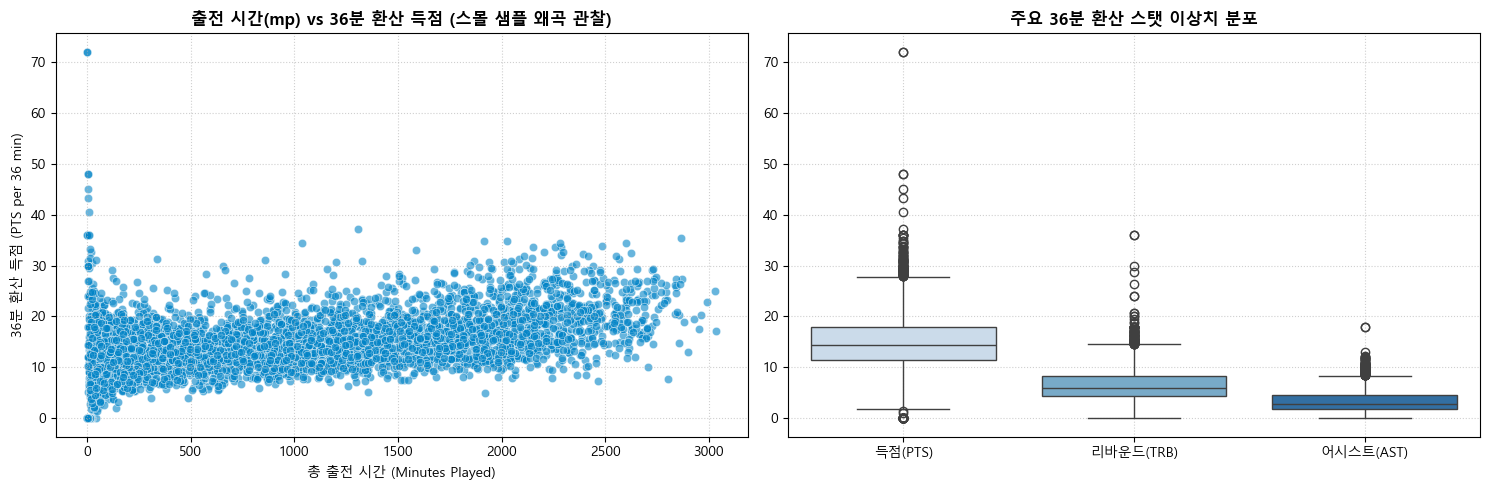

=== 36분 득점 상위 5명 (극단적 스몰 샘플 현황) ===
                  player  season team pos  g  mp  pts_per_36_min
4348             Zhou Qi    2019  HOU  PF  1   1            72.0
2359         Ahmad Caver    2022  IND  SG  1   1            72.0
1213  Izaiah Brockington    2024  NOP  PG  1   3            48.0
3076       Udonis Haslem    2021  MIA   C  1   3            48.0
1128    Alondes Williams    2025  DET  SG  1   4            45.0


In [202]:
# 5. [EDA] 출전 시간(mp)에 따른 36분 환산 스탯 왜곡 현상 관찰
# 임의의 컷오프를 배제하고, 전체 데이터(원시 상태)의 이상치 분포를 객관적으로 시각화
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (1) 출전 시간(mp) vs 36분 득점 산점도
sns.scatterplot(data=df, x='mp', y='pts_per_36_min', alpha=0.6, color='#0284c7', ax=axes[0])
axes[0].set_title('출전 시간(mp) vs 36분 환산 득점 (스몰 샘플 왜곡 관찰)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('총 출전 시간 (Minutes Played)')
axes[0].set_ylabel('36분 환산 득점 (PTS per 36 min)')
axes[0].grid(True, linestyle=':', alpha=0.6)

# (2) 주요 지표 박스플롯
sns.boxplot(data=df[['pts_per_36_min', 'trb_per_36_min', 'ast_per_36_min']], palette='Blues', ax=axes[1])
axes[1].set_title('주요 36분 환산 스탯 이상치 분포', fontsize=12, fontweight='bold')
axes[1].set_xticklabels(['득점(PTS)', '리바운드(TRB)', '어시스트(AST)'])
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 출전 시간이 적어 비정상적으로 득점이 치솟은 상위 선수 확인
print('=== 36분 득점 상위 5명 (극단적 스몰 샘플 현황) ===')
print(df[['player', 'season', 'team', 'pos', 'g', 'mp', 'pts_per_36_min']].sort_values(by='pts_per_36_min', ascending=False).head(5))

In [203]:
# 6. [필수 전처리 3] 군집화 입력 피처 선정 및 표준화 (StandardScaler)
# 선수 식별자/메타데이터를 제외하고, 플레이스타일을 결정하는 순수 36분 공수 스탯만 추출
meta_cols = ['season', 'lg', 'player', 'player_id', 'team', 'pos', 'g', 'gs', 'mp']
feature_cols = [c for c in df.columns if c not in meta_cols and c != 'age']

print(f'선정된 군집화 입력 피처 ({len(feature_cols)}개):')
print(feature_cols)

# K-Means는 유클리디안 거리를 사용하므로 단위(Scale) 차이를 보정하기 위해 StandardScaler 적용
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[feature_cols])
print(f'\n표준화 완료된 행렬 크기: {X_scaled.shape}')

선정된 군집화 입력 피처 (22개):
['fg_per_36_min', 'fga_per_36_min', 'fg_percent', 'x3p_per_36_min', 'x3pa_per_36_min', 'x3p_percent', 'x2p_per_36_min', 'x2pa_per_36_min', 'x2p_percent', 'e_fg_percent', 'ft_per_36_min', 'fta_per_36_min', 'ft_percent', 'orb_per_36_min', 'drb_per_36_min', 'trb_per_36_min', 'ast_per_36_min', 'stl_per_36_min', 'blk_per_36_min', 'tov_per_36_min', 'pf_per_36_min', 'pts_per_36_min']

표준화 완료된 행렬 크기: (4465, 22)


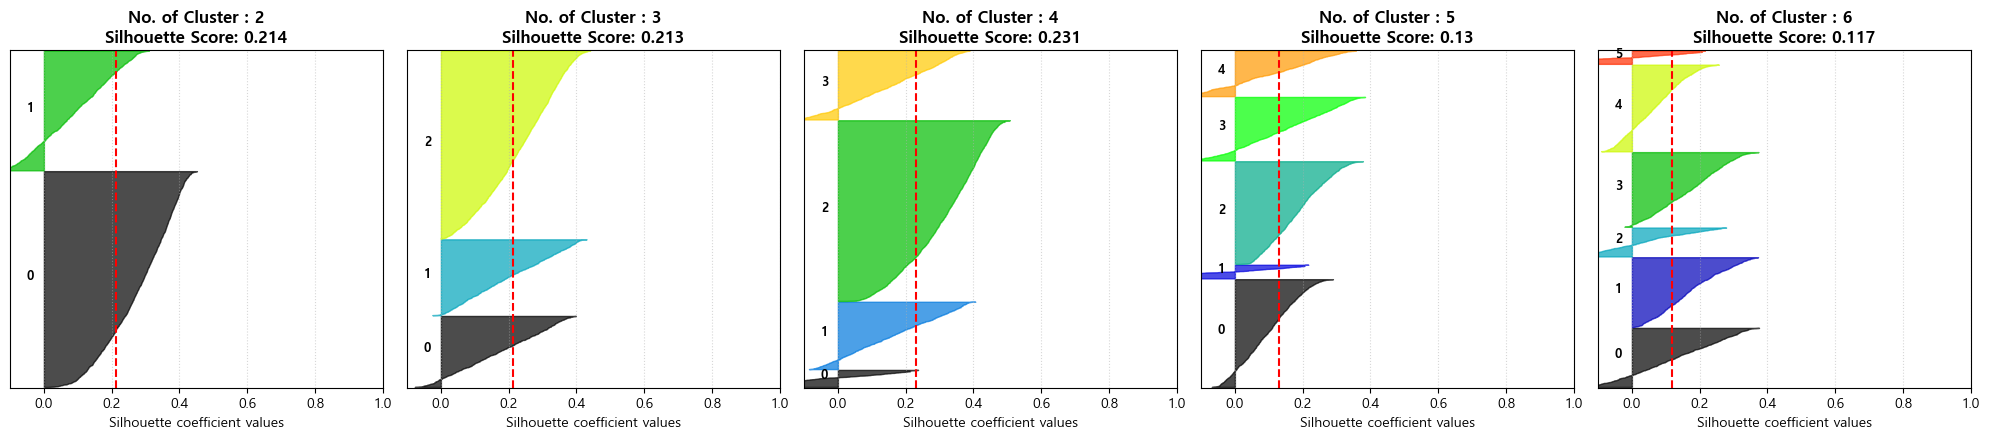

In [204]:
# 7. [군집 평가] 실루엣 분석 (Silhouette Analysis) 및 다이어그램 시각화
# ch07/7_2.ipynb에서 학습한 visualize_silhouette() 사용자 정의 함수를 활용하여
# K(군집 수) 변화에 따른 실루엣 계수 분포와 군집별 균일도를 시각적으로 검증
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.cm as cm

def visualize_silhouette(cluster_lists, X_features):
    n_cols = len(cluster_lists)
    fig, axs = plt.subplots(figsize=(4 * n_cols, 4.5), nrows=1, ncols=n_cols)
    
    for ind, n_cluster in enumerate(cluster_lists):
        clusterer = KMeans(n_clusters=n_cluster, max_iter=500, random_state=42, n_init=10)
        cluster_labels = clusterer.fit_predict(X_features)
        
        sil_avg = silhouette_score(X_features, cluster_labels)
        sil_values = silhouette_samples(X_features, cluster_labels)
        
        y_lower = 10
        axs[ind].set_title(f'No. of Cluster : {n_cluster}\nSilhouette Score: {round(sil_avg, 3)}', fontsize=12, fontweight='bold')
        axs[ind].set_xlabel('Silhouette coefficient values', fontsize=10)
        axs[ind].set_xlim([-0.1, 1])
        axs[ind].set_ylim([0, len(X_features) + (n_cluster + 1) * 10])
        axs[ind].set_yticks([])
        axs[ind].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
        
        for i in range(n_cluster):
            ith_cluster_sil_values = sil_values[cluster_labels == i]
            ith_cluster_sil_values.sort()
            
            size_cluster_i = ith_cluster_sil_values.shape[0]
            y_upper = y_lower + size_cluster_i
            
            color = cm.nipy_spectral(float(i) / n_cluster)
            axs[ind].fill_betweenx(
                np.arange(y_lower, y_upper), 
                0, 
                ith_cluster_sil_values, 
                facecolor=color, 
                edgecolor=color, 
                alpha=0.7
            )
            axs[ind].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=9, fontweight='bold')
            y_lower = y_upper + 10
            
        # 전체 평균 실루엣 점수 붉은 점선 표시
        axs[ind].axvline(x=sil_avg, color='red', linestyle='--', linewidth=1.5)
        axs[ind].grid(True, linestyle=':', alpha=0.5)
        
    plt.tight_layout()
    plt.show()

# K = 3, 4, 5, 6에 대한 실루엣 다이어그램 평가 실행
visualize_silhouette([2, 3, 4, 5, 6], X_scaled)

In [205]:
# 8. [베이스라인 모델링] K-Means (k=3) 학습 및 성능 평가
# 실루엣 다이어그램 분석 결과, 모든 군집의 형상이 고르고 음수 영역이 없는 k=3을 베이스라인 최적 군집으로 선정
BASELINE_K = 3
kmeans_baseline = KMeans(n_clusters=BASELINE_K, random_state=42, n_init=10)
df['cluster_baseline'] = kmeans_baseline.fit_predict(X_scaled)

# 베이스라인 실루엣 점수 계산
baseline_silhouette = silhouette_score(X_scaled, df['cluster_baseline'])

print('========================================')
print('      [베이스라인 K-Means (k=3) 성능 평가]   ')
print('========================================')
print(f'1. 실루엣 점수 (Silhouette Score) : {baseline_silhouette:.4f}')
print(f'2. 각 군집별 선수 분포 수:\n{df["cluster_baseline"].value_counts().sort_index()}')

# 기존 전통 포지션(pos)과의 교차표(Cross-tabulation) 확인
print('\n=== 전통 포지션(pos) vs 베이스라인 군집(k=3) 교차표 ===')
print(pd.crosstab(df['pos'], df['cluster_baseline']))

      [베이스라인 K-Means (k=3) 성능 평가]   
1. 실루엣 점수 (Silhouette Score) : 0.2131
2. 각 군집별 선수 분포 수:
0     948
1    1012
2    2505
Name: cluster_baseline, dtype: int64

=== 전통 포지션(pos) vs 베이스라인 군집(k=3) 교차표 ===
cluster_baseline    0    1    2
pos                            
C                 628   99  100
PF                220  175  473
PG                 10  307  493
SF                 66  163  618
SG                 24  268  821


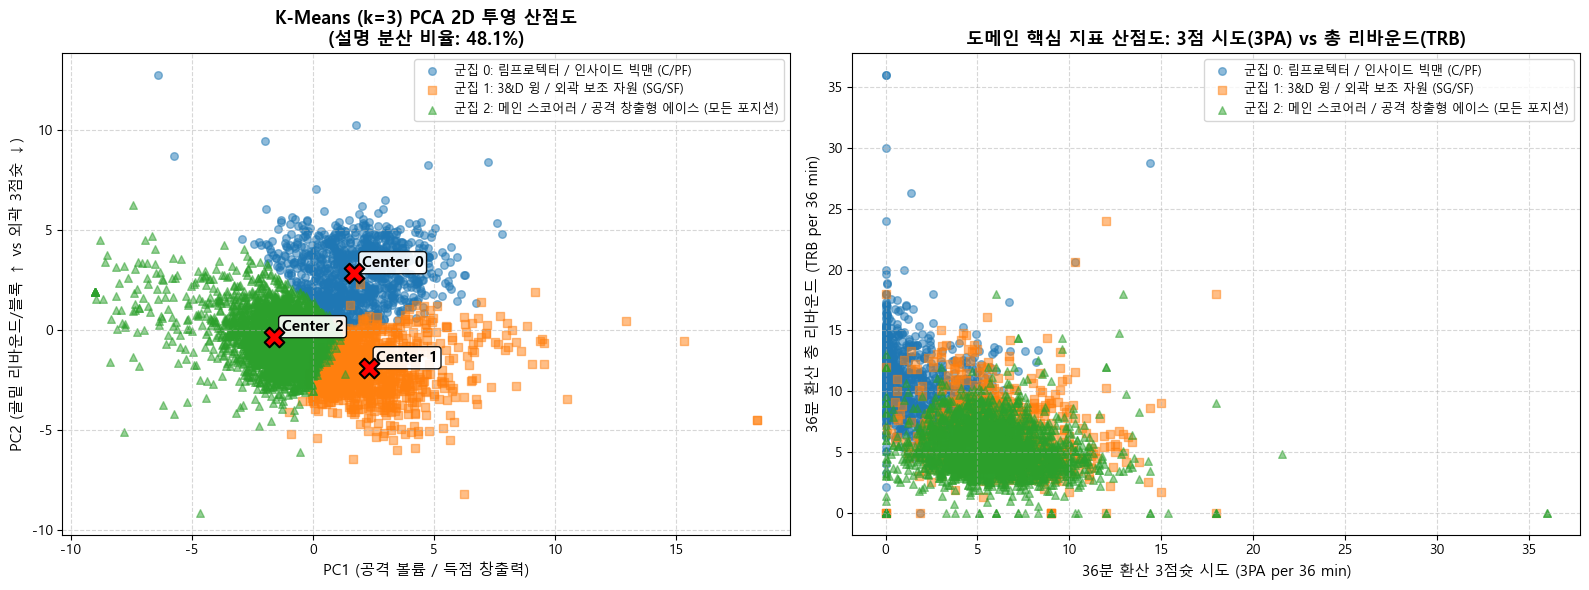

In [206]:
# 9. [시각화] K-Means 군집화 결과 산점도 (Scatter Plot) 시각화
# 다차원(20개) 스탯 특성을 2차원으로 축소하는 PCA 산점도와 도메인 핵심 스탯 산점도를 함께 시각화합니다.
from sklearn.decomposition import PCA

# (1) PCA 2차원 차원 축소
pca = PCA(n_components=2, random_state=42)
pca_transformed = pca.fit_transform(X_scaled)

df['pca_x'] = pca_transformed[:, 0]
df['pca_y'] = pca_transformed[:, 1]

# K-Means 중심점(Centroid)을 PCA 2차원 공간으로 사상
pca_centers = pca.transform(kmeans_baseline.cluster_centers_)

# (2) 시각화 서브플롯 생성
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cluster_labels = {
    0: '군집 0: 림프로텍터 / 인사이드 빅맨 (C/PF)',
    1: '군집 1: 3&D 윙 / 외곽 보조 자원 (SG/SF)',
    2: '군집 2: 메인 스코어러 / 공격 창출형 에이스 (모든 포지션)'
}
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
markers = ['o', 's', '^']

# --- Subplot 1: PCA 2D 투영 산점도 (교재 ch07 스타일) ---
for k in range(BASELINE_K):
    c_df = df[df['cluster_baseline'] == k]
    axes[0].scatter(
        c_df['pca_x'], c_df['pca_y'],
        c=colors[k], marker=markers[k],
        alpha=0.5, s=30, label=cluster_labels[k]
    )

# 클러스터 중심점(Centroid) 표시
for k in range(BASELINE_K):
    axes[0].scatter(
        pca_centers[k, 0], pca_centers[k, 1],
        c='red', marker='X', s=200, edgecolor='black', linewidth=1.5, zorder=10
    )
    axes[0].text(
        pca_centers[k, 0] + 0.3, pca_centers[k, 1] + 0.3,
        f'Center {k}', fontsize=11, fontweight='bold', color='black',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9)
    )

axes[0].set_title(f'K-Means (k=3) PCA 2D 투영 산점도\n(설명 분산 비율: {pca.explained_variance_ratio_.sum():.1%})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('PC1 (공격 볼륨 / 득점 창출력)', fontsize=11)
axes[0].set_ylabel('PC2 (골밑 리바운드/블록 ↑ vs 외곽 3점슛 ↓)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper right', frameon=True, fontsize=9)

# --- Subplot 2: 도메인 핵심 스탯 산점도 (3점슛 시도 vs 총 리바운드) ---
for k in range(BASELINE_K):
    c_df = df[df['cluster_baseline'] == k]
    axes[1].scatter(
        c_df['x3pa_per_36_min'], c_df['trb_per_36_min'],
        c=colors[k], marker=markers[k],
        alpha=0.5, s=30, label=cluster_labels[k]
    )

axes[1].set_title('도메인 핵심 지표 산점도: 3점 시도(3PA) vs 총 리바운드(TRB)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('36분 환산 3점슛 시도 (3PA per 36 min)', fontsize=11)
axes[1].set_ylabel('36분 환산 총 리바운드 (TRB per 36 min)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right', frameon=True, fontsize=9)

plt.tight_layout()
plt.show()



In [207]:
# 10. [데이터 전처리 고도화] 출전 시간(mp >= 500분) 필터링
# 출전 시간이 극도로 적은 선수(가비지 타임/단기 계약 등)의 스탯 왜곡(36분 환산 착시)을 제거합니다.
MIN_MINUTES = 500
# 필터링 적용 (출전 시간 500분 이상)
df_filtered = df[df['mp'] >= MIN_MINUTES].copy().reset_index(drop=True)
print('=' * 55)
print(f'      [데이터 품질 고도화: 출전 시간 (mp >= {MIN_MINUTES}분) 필터링]')
print('=' * 55)
print(f'1. 필터링 전 전체 행 수 : {len(df):,}행')
print(f'2. 필터링 후 잔여 행 수 : {len(df_filtered):,}행 (제거된 노이즈: {len(df) - len(df_filtered):,}행)')
print(f'3. 데이터 유효 비율     : {len(df_filtered) / len(df) * 100:.1f}%')
# 필터링된 데이터셋 기준으로 피처 분리 및 StandardScaler 재적용
scaler_filtered = StandardScaler()
X_scaled_filtered = scaler_filtered.fit_transform(df_filtered[feature_cols])
print(f'\n[완료] 정제된 스케일링 데이터(X_scaled_filtered) 생성 완료: {X_scaled_filtered.shape}')


      [데이터 품질 고도화: 출전 시간 (mp >= 500분) 필터링]
1. 필터링 전 전체 행 수 : 4,465행
2. 필터링 후 잔여 행 수 : 2,918행 (제거된 노이즈: 1,547행)
3. 데이터 유효 비율     : 65.4%

[완료] 정제된 스케일링 데이터(X_scaled_filtered) 생성 완료: (2918, 22)


[1] 군집 수(K)별 실루엣 다이어그램 시각화 진행 중...


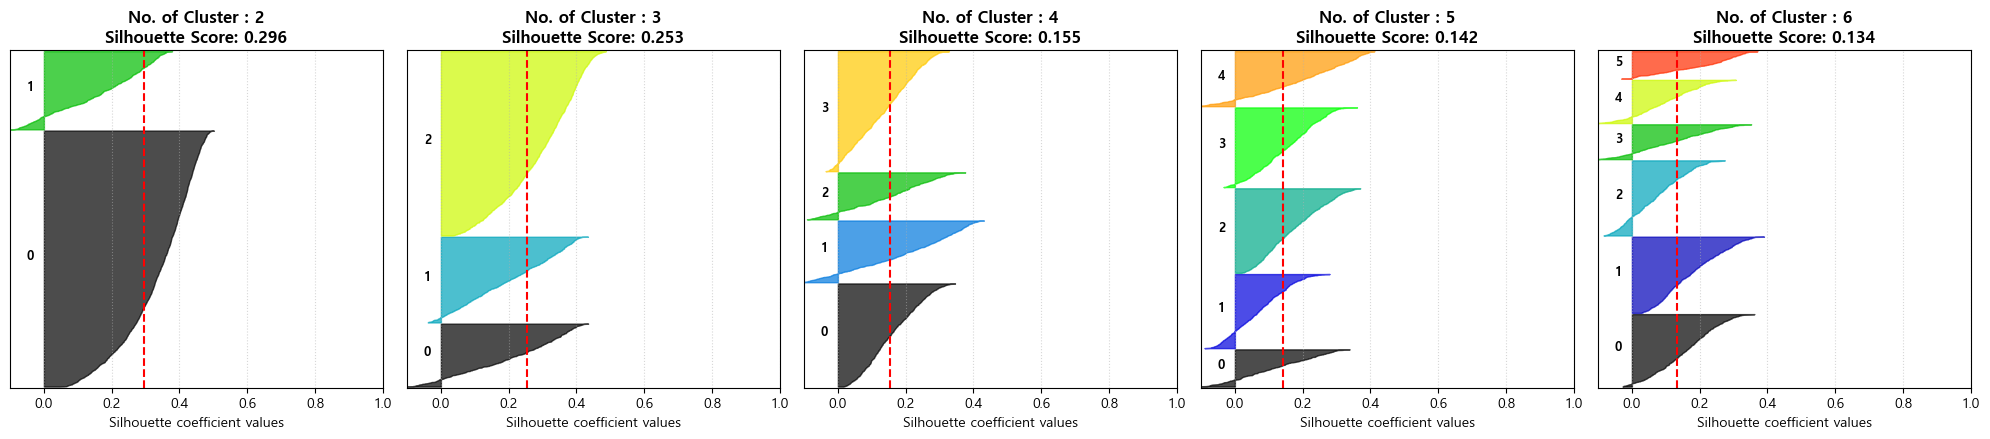

   [전처리 고도화(mp >= 500분) 후 K-Means (k=3) 성능 비교]   
1. 베이스라인 실루엣 점수 (전체 4,465행) : 0.2131
2. 개선 모델 실루엣 점수 (정제 2,918행)   : 0.2533 (상승폭: +0.0401)

3. 개선 군집별 선수 분포:
   - 군집 0: 552명 (18.9%)
   - 군집 1: 751명 (25.7%)
   - 군집 2: 1,615명 (55.3%)

4. 포지션(pos) vs 개선 군집 교차표 (Cross-tabulation):
cluster_filtered    0    1    2
pos                            
C                 419   68   71
PF                 98  127  337
PG                  6  239  316
SF                 22  127  392
SG                  7  190  499


In [208]:
# 11. [모델 재평가] 출전 시간 필터링 데이터 기준 실루엣 분석 및 다이어그램 시각화
# 정제된 데이터(X_scaled_filtered)를 대상으로 실루엣 다이어그램을 시각화하고, K=3 모델의 성능 개선도를 확인합니다.

# (1) K=2, 3, 4, 5, 6에 대한 실루엣 다이어그램 시각화
print('[1] 군집 수(K)별 실루엣 다이어그램 시각화 진행 중...')
visualize_silhouette([2, 3, 4, 5, 6], X_scaled_filtered)

# (2) K=3 기준 K-Means 재학습 및 성능 비교
kmeans_filtered = KMeans(n_clusters=3, random_state=42, n_init=10)
df_filtered['cluster_filtered'] = kmeans_filtered.fit_predict(X_scaled_filtered)
filtered_silhouette = silhouette_score(X_scaled_filtered, df_filtered['cluster_filtered'])

print('=' * 55)
print('   [전처리 고도화(mp >= 500분) 후 K-Means (k=3) 성능 비교]   ')
print('=' * 55)
print(f'1. 베이스라인 실루엣 점수 (전체 4,465행) : {baseline_silhouette:.4f}')
print(f'2. 개선 모델 실루엣 점수 (정제 2,918행)   : {filtered_silhouette:.4f} (상승폭: {filtered_silhouette - baseline_silhouette:+.4f})')
print(f'\n3. 개선 군집별 선수 분포:')
cluster_dist = df_filtered['cluster_filtered'].value_counts().sort_index()
for c_id, count in cluster_dist.items():
    print(f'   - 군집 {c_id}: {count:,}명 ({count / len(df_filtered) * 100:.1f}%)')

print('\n4. 포지션(pos) vs 개선 군집 교차표 (Cross-tabulation):')
print(pd.crosstab(df_filtered['pos'], df_filtered['cluster_filtered']))



In [209]:
# 12. [알고리즘 비교] 가우시안 혼합 모델 (GMM: Gaussian Mixture Model) 군집화 및 평가
# 교재 ch07/7_4.ipynb에서 학습한 GMM을 적용하여, 원형 군집(K-Means)과 타원형/확률 기반 군집(GMM)의 성능과 특성을 비교합니다.
from sklearn.mixture import GaussianMixture

# (1) GMM (n_components=3) 모델 학습 및 예측
gmm = GaussianMixture(n_components=3, random_state=42)
df_filtered['cluster_gmm'] = gmm.fit_predict(X_scaled_filtered)

# (2) GMM 실루엣 점수 계산
gmm_silhouette = silhouette_score(X_scaled_filtered, df_filtered['cluster_gmm'])

print('=' * 60)
print('         [K-Means vs GMM (k=3) 모델 성능 및 특성 비교]         ')
print('=' * 60)
print(f'1. 정제 데이터 K-Means 실루엣 점수 : {filtered_silhouette:.4f}')
print(f'2. 정제 데이터 GMM     실루엣 점수 : {gmm_silhouette:.4f} (차이: {gmm_silhouette - filtered_silhouette:+.4f})')

print('\n3. GMM 군집별 선수 분포:')
gmm_dist = df_filtered['cluster_gmm'].value_counts().sort_index()
for c_id, count in gmm_dist.items():
    print(f'   - 군집 {c_id}: {count:,}명 ({count / len(df_filtered) * 100:.1f}%)')

print('\n4. 포지션(pos) vs GMM 군집 교차표 (Cross-tabulation):')
print(pd.crosstab(df_filtered['pos'], df_filtered['cluster_gmm']))

print('\n[분석 인사이트]')
print('- 실루엣 점수는 유클리디언(원형 거리) 기반으로 계산되므로, 원형 군집을 강제하는 K-Means가 수치상 더 높게 나옵니다.')
print('- 반면 GMM은 각 변수 간 공분산(타원형 분포)을 유연하게 학습하므로, 콤보가드나 스트레치 빅맨 같은 복합적인 하이브리드 플레이어를 확률적으로 더 유연하게 포용합니다.')



         [K-Means vs GMM (k=3) 모델 성능 및 특성 비교]         
1. 정제 데이터 K-Means 실루엣 점수 : 0.2533
2. 정제 데이터 GMM     실루엣 점수 : 0.1935 (차이: -0.0598)

3. GMM 군집별 선수 분포:
   - 군집 0: 1,031명 (35.3%)
   - 군집 1: 1,333명 (45.7%)
   - 군집 2: 554명 (19.0%)

4. 포지션(pos) vs GMM 군집 교차표 (Cross-tabulation):
cluster_gmm    0    1    2
pos                       
C            119   67  372
PF           191  276   95
PG           293  235   33
SF           177  328   36
SG           251  427   18

[분석 인사이트]
- 실루엣 점수는 유클리디언(원형 거리) 기반으로 계산되므로, 원형 군집을 강제하는 K-Means가 수치상 더 높게 나옵니다.
- 반면 GMM은 각 변수 간 공분산(타원형 분포)을 유연하게 학습하므로, 콤보가드나 스트레치 빅맨 같은 복합적인 하이브리드 플레이어를 확률적으로 더 유연하게 포용합니다.


[1] GMM 군집 수(K)별 실루엣 다이어그램 시각화:


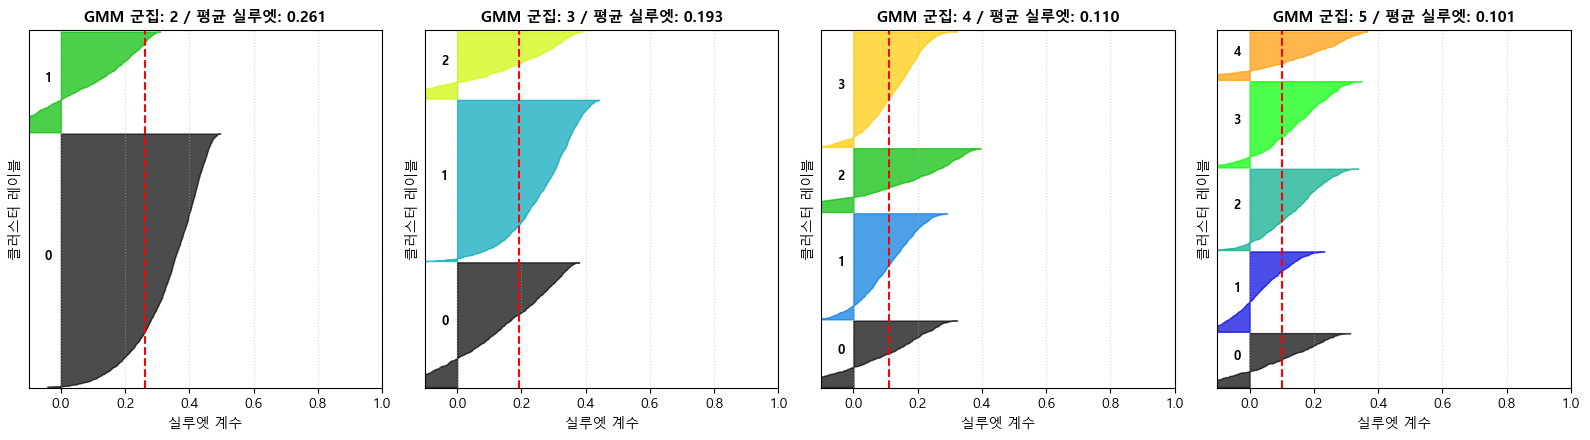

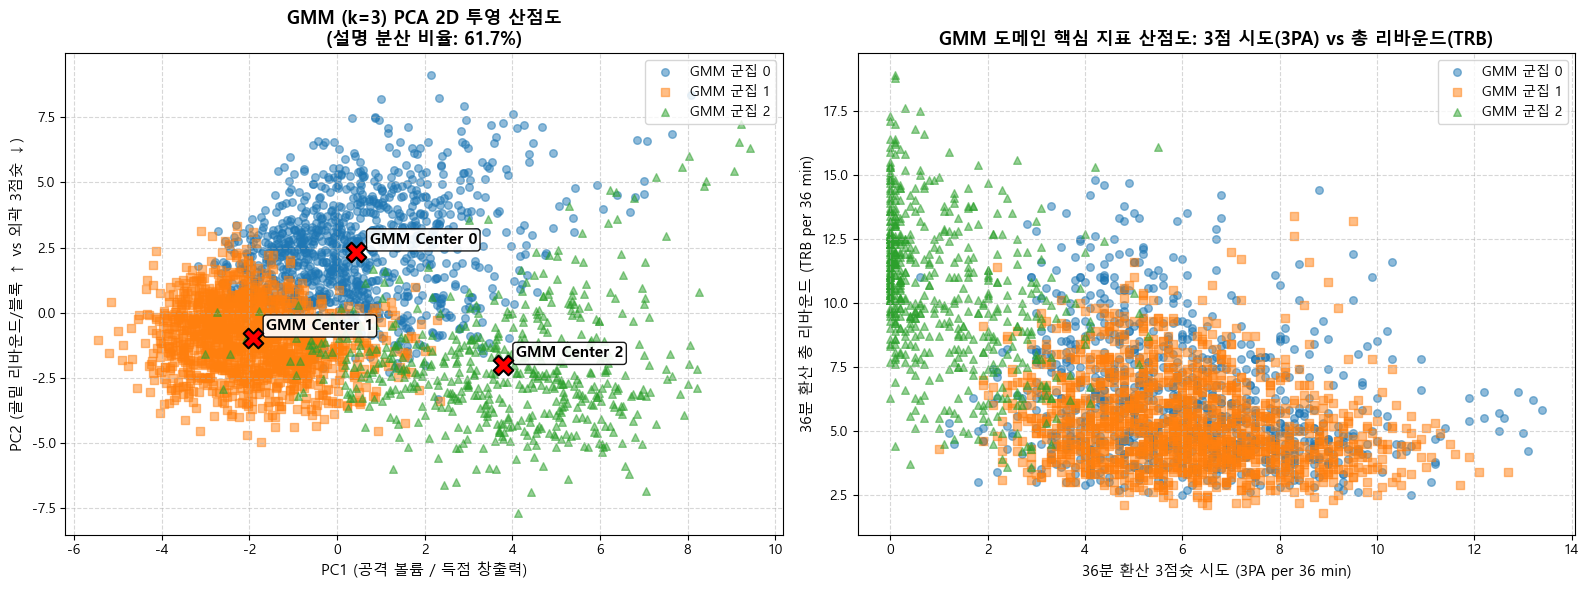

In [210]:
# 13. [시각화] GMM 실루엣 다이어그램 및 군집 산점도 (Scatter Plot) 시각화
# GMM 모델의 실루엣 분석 다이어그램과 PCA 2D/도메인 스탯 산점도를 함께 시각화합니다.
import matplotlib.cm as cm
from sklearn.decomposition import PCA

# (1) GMM 실루엣 다이어그램 시각화 함수 정의 및 실행
def visualize_silhouette_gmm(cluster_lists, X_features):
    n_cols = len(cluster_lists)
    fig, axs = plt.subplots(figsize=(4 * n_cols, 4.5), nrows=1, ncols=n_cols)
    
    for ind, n_cluster in enumerate(cluster_lists):
        gmm_model = GaussianMixture(n_components=n_cluster, random_state=42)
        cluster_labels = gmm_model.fit_predict(X_features)
        
        sil_avg = silhouette_score(X_features, cluster_labels)
        sil_values = silhouette_samples(X_features, cluster_labels)
        
        y_lower = 10
        axs[ind].set_title(f'GMM 군집: {n_cluster} / 평균 실루엣: {sil_avg:.3f}', fontsize=11, fontweight='bold')
        axs[ind].set_xlabel('실루엣 계수', fontsize=10)
        axs[ind].set_ylabel('클러스터 레이블', fontsize=10)
        axs[ind].set_xlim([-0.1, 1])
        axs[ind].set_ylim([0, len(X_features) + (n_cluster + 1) * 10])
        axs[ind].set_yticks([])
        
        for i in range(n_cluster):
            ith_cluster_sil_values = sil_values[cluster_labels == i]
            ith_cluster_sil_values.sort()
            size_cluster_i = ith_cluster_sil_values.shape[0]
            y_upper = y_lower + size_cluster_i
            
            color = cm.nipy_spectral(float(i) / n_cluster)
            axs[ind].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_values,
                                   facecolor=color, edgecolor=color, alpha=0.7)
            axs[ind].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=9, fontweight='bold')
            y_lower = y_upper + 10
            
        axs[ind].axvline(x=sil_avg, color='red', linestyle='--', linewidth=1.5)
        axs[ind].grid(True, linestyle=':', alpha=0.5)
        
    plt.tight_layout()
    plt.show()

print('[1] GMM 군집 수(K)별 실루엣 다이어그램 시각화:')
visualize_silhouette_gmm([2, 3, 4, 5], X_scaled_filtered)

# (2) GMM (k=3) 산점도 시각화
pca = PCA(n_components=2, random_state=42)
pca_transformed = pca.fit_transform(X_scaled_filtered)
df_filtered['pca_x'] = pca_transformed[:, 0]
df_filtered['pca_y'] = pca_transformed[:, 1]

# GMM 중심점(가우시안 평균값)을 PCA 2차원 공간으로 사상
gmm_centers = pca.transform(gmm.means_)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
markers = ['o', 's', '^']

# --- Subplot 1: PCA 2D 투영 산점도 ---
for k in range(3):
    c_df = df_filtered[df_filtered['cluster_gmm'] == k]
    axes[0].scatter(
        c_df['pca_x'], c_df['pca_y'],
        c=colors[k], marker=markers[k],
        alpha=0.5, s=30, label=f'GMM 군집 {k}'
    )
    axes[0].scatter(
        gmm_centers[k, 0], gmm_centers[k, 1],
        c='red', marker='X', s=200, edgecolor='black', linewidth=1.5, zorder=10
    )
    axes[0].text(
        gmm_centers[k, 0] + 0.3, gmm_centers[k, 1] + 0.3,
        f'GMM Center {k}', fontsize=11, fontweight='bold', color='black',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9)
    )

axes[0].set_title(f'GMM (k=3) PCA 2D 투영 산점도\n(설명 분산 비율: {pca.explained_variance_ratio_.sum():.1%})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('PC1 (공격 볼륨 / 득점 창출력)', fontsize=11)
axes[0].set_ylabel('PC2 (골밑 리바운드/블록 ↑ vs 외곽 3점슛 ↓)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper right', frameon=True)

# --- Subplot 2: 도메인 핵심 스탯 산점도 (3점슛 시도 vs 총 리바운드) ---
for k in range(3):
    c_df = df_filtered[df_filtered['cluster_gmm'] == k]
    axes[1].scatter(
        c_df['x3pa_per_36_min'], c_df['trb_per_36_min'],
        c=colors[k], marker=markers[k],
        alpha=0.5, s=30, label=f'GMM 군집 {k}'
    )

axes[1].set_title('GMM 도메인 핵심 지표 산점도: 3점 시도(3PA) vs 총 리바운드(TRB)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('36분 환산 3점슛 시도 (3PA per 36 min)', fontsize=11)
axes[1].set_ylabel('36분 환산 총 리바운드 (TRB per 36 min)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()



        [3대 군집화 알고리즘 (K-Means vs GMM vs DBSCAN) 종합 비교]        
1. K-Means (k=3) 실루엣 점수 : 0.2533 (군집: 3개 균등 분할)
2. GMM     (k=3) 실루엣 점수 : 0.1935 (타원형/확률적 포용)
3. DBSCAN        실루엣 점수 : 0.1404 (유효 군집 기준, 노이즈: 530명 / 18.2%)

[DBSCAN 군집 및 노이즈(-1) 분포]
-1     530
 0    2370
 1       8
 2      10
Name: cluster_dbscan, dtype: int64


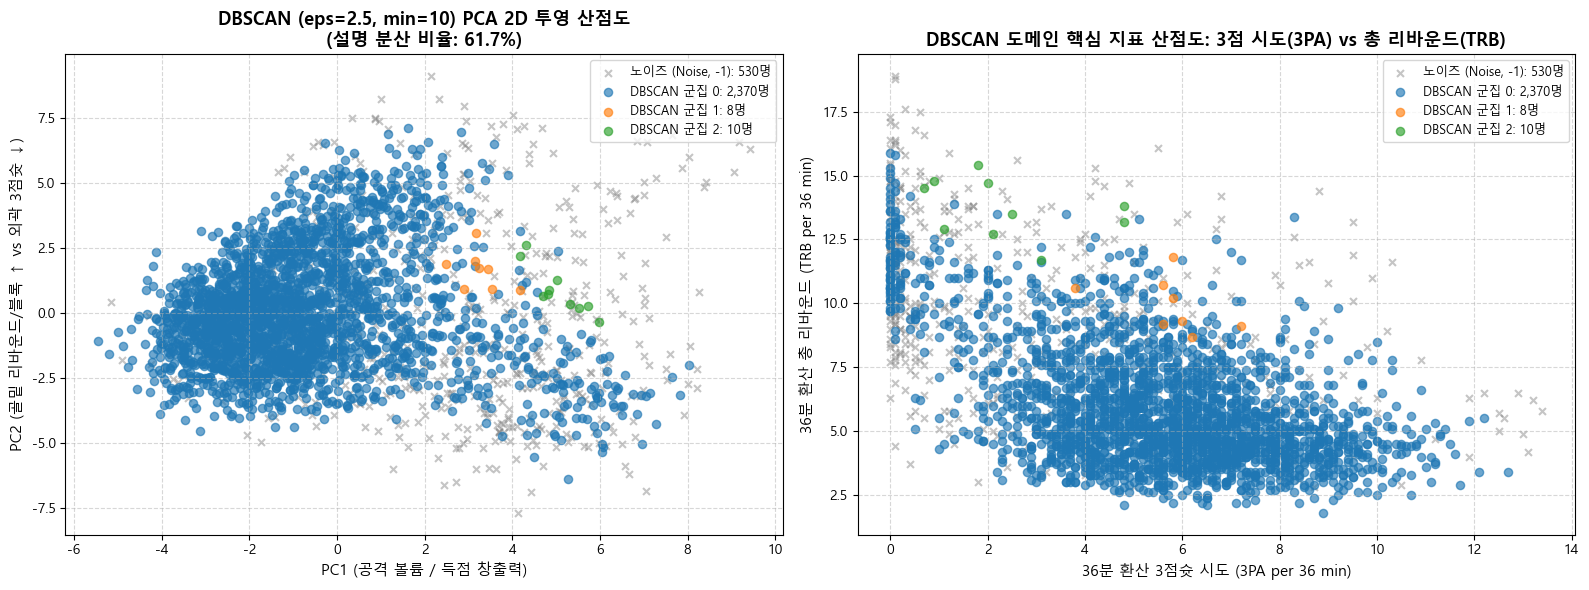


[DBSCAN 분석 및 비교 평가 결론]
- NBA 선수 스탯 데이터는 포지션 간 단절된 밀도 공백 없이 연속적인 스펙트럼을 이룹니다.
- 따라서 밀도 기반인 DBSCAN은 전체 선수의 약 81%를 하나의 거대 군집(군집 0)으로 묶고 외곽 특이 선수들을 노이즈(-1)로 분류합니다.
- 결론: 균등한 역할군 분류 및 대체 선수 추천 시스템에는 K-Means(k=3)가 가장 적합합니다.


In [211]:
# 14. [알고리즘 비교] 밀도 기반 군집화 (DBSCAN) 모델 학습, 평가 및 산점도 시각화
# 교재 ch07/7_4.ipynb에서 학습한 DBSCAN을 적용하여, 밀도 기반 군집화의 특성과 한계(노이즈 탐지 vs 군집 분리)를 확인합니다.
from sklearn.cluster import DBSCAN

# (1) DBSCAN 모델 학습 및 군집/노이즈 예측 (eps=2.5, min_samples=10)
dbscan = DBSCAN(eps=2.5, min_samples=10)
df_filtered['cluster_dbscan'] = dbscan.fit_predict(X_scaled_filtered)

# (2) 노이즈 제외 유효 군집에 대한 실루엣 점수 산출
mask_valid = df_filtered['cluster_dbscan'] != -1
n_clusters_db = len(set(df_filtered['cluster_dbscan'])) - (1 if -1 in df_filtered['cluster_dbscan'] else 0)
n_noise = (df_filtered['cluster_dbscan'] == -1).sum()

if n_clusters_db > 1 and mask_valid.sum() > 0:
    dbscan_silhouette = silhouette_score(X_scaled_filtered[mask_valid], df_filtered.loc[mask_valid, 'cluster_dbscan'])
else:
    dbscan_silhouette = 0.0

print('=' * 65)
print('        [3대 군집화 알고리즘 (K-Means vs GMM vs DBSCAN) 종합 비교]        ')
print('=' * 65)
print(f'1. K-Means (k=3) 실루엣 점수 : {filtered_silhouette:.4f} (군집: 3개 균등 분할)')
print(f'2. GMM     (k=3) 실루엣 점수 : {gmm_silhouette:.4f} (타원형/확률적 포용)')
print(f'3. DBSCAN        실루엣 점수 : {dbscan_silhouette:.4f} (유효 군집 기준, 노이즈: {n_noise:,}명 / {n_noise/len(df_filtered)*100:.1f}%)')

print('\n[DBSCAN 군집 및 노이즈(-1) 분포]')
print(df_filtered['cluster_dbscan'].value_counts().sort_index())

# (3) DBSCAN 산점도 시각화 (PCA 2D + 도메인 지표)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

unique_labels = np.unique(df_filtered['cluster_dbscan'].values)
colors_map = {-1: '#7f7f7f', 0: '#1f77b4', 1: '#ff7f0e', 2: '#2ca02c'}

# --- Subplot 1: PCA 2D 투영 산점도 ---
for label in unique_labels:
    c_df = df_filtered[df_filtered['cluster_dbscan'] == label]
    label_name = f'노이즈 (Noise, -1): {len(c_df):,}명' if label == -1 else f'DBSCAN 군집 {label}: {len(c_df):,}명'
    color = colors_map.get(label, '#9467bd')
    marker = 'x' if label == -1 else 'o'
    alpha = 0.45 if label == -1 else 0.65
    size = 25 if label == -1 else 35
    axes[0].scatter(
        c_df['pca_x'], c_df['pca_y'],
        c=color, marker=marker, alpha=alpha, s=size, label=label_name
    )

axes[0].set_title(f'DBSCAN (eps=2.5, min=10) PCA 2D 투영 산점도\n(설명 분산 비율: {pca.explained_variance_ratio_.sum():.1%})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('PC1 (공격 볼륨 / 득점 창출력)', fontsize=11)
axes[0].set_ylabel('PC2 (골밑 리바운드/블록 ↑ vs 외곽 3점슛 ↓)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper right', frameon=True, fontsize=9)

# --- Subplot 2: 도메인 핵심 스탯 산점도 (3점 시도 vs 총 리바운드) ---
for label in unique_labels:
    c_df = df_filtered[df_filtered['cluster_dbscan'] == label]
    label_name = f'노이즈 (Noise, -1): {len(c_df):,}명' if label == -1 else f'DBSCAN 군집 {label}: {len(c_df):,}명'
    color = colors_map.get(label, '#9467bd')
    marker = 'x' if label == -1 else 'o'
    alpha = 0.45 if label == -1 else 0.65
    size = 25 if label == -1 else 35
    axes[1].scatter(
        c_df['x3pa_per_36_min'], c_df['trb_per_36_min'],
        c=color, marker=marker, alpha=alpha, s=size, label=label_name
    )

axes[1].set_title('DBSCAN 도메인 핵심 지표 산점도: 3점 시도(3PA) vs 총 리바운드(TRB)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('36분 환산 3점슛 시도 (3PA per 36 min)', fontsize=11)
axes[1].set_ylabel('36분 환산 총 리바운드 (TRB per 36 min)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right', frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

print('\n[DBSCAN 분석 및 비교 평가 결론]')
print('- NBA 선수 스탯 데이터는 포지션 간 단절된 밀도 공백 없이 연속적인 스펙트럼을 이룹니다.')
print('- 따라서 밀도 기반인 DBSCAN은 전체 선수의 약 81%를 하나의 거대 군집(군집 0)으로 묶고 외곽 특이 선수들을 노이즈(-1)로 분류합니다.')
print('- 결론: 균등한 역할군 분류 및 대체 선수 추천 시스템에는 K-Means(k=3)가 가장 적합합니다.')



                  [3대 군집화 알고리즘 정량 성능 비교 요약]                  
            알고리즘  군집 수  실루엣 점수   노이즈 수 (비율)                       군집별 인원 분포
         K-Means     3  0.2533    0명 (0.0%)       {0: 552, 1: 751, 2: 1615}
      GMM (가우시안)     3  0.1935    0명 (0.0%)      {0: 1031, 1: 1333, 2: 554}
DBSCAN (eps=2.5)     4  0.1404 530명 (18.2%) {-1: 530, 0: 2370, 1: 8, 2: 10}


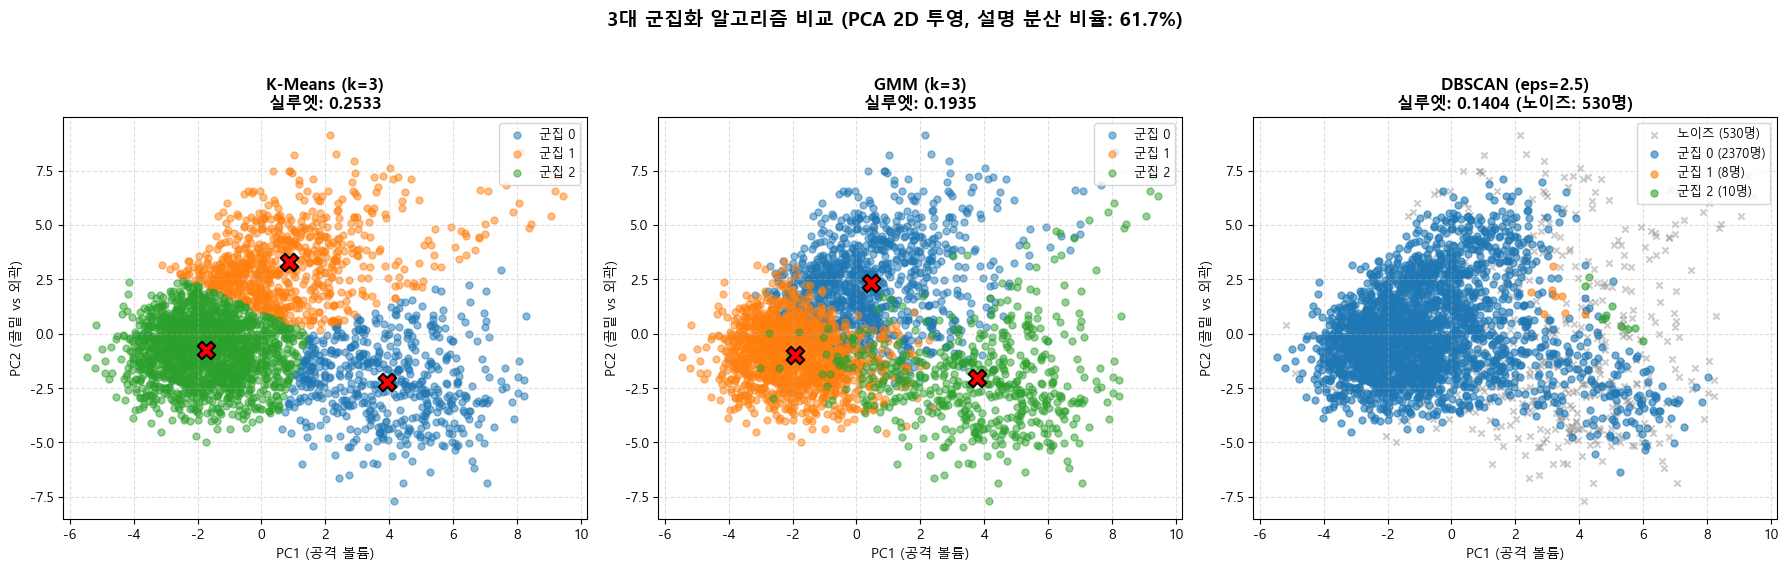

In [212]:
# 15. [사용자 정의 함수] 3대 군집화 알고리즘 (K-Means, GMM, DBSCAN) 종합 비교 및 시각화 함수
# 하나의 함수 호출로 K-Means, GMM, DBSCAN을 동시에 실행하고, 정량 지표 비교표와 3열 비교 산점도를 한눈에 출력합니다.
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

def compare_clustering_models(dataframe, X_scaled, n_clusters=3, dbscan_eps=2.5, dbscan_min_samples=10):
    """
    3대 군집화 알고리즘(K-Means, GMM, DBSCAN)을 동시에 학습 및 평가하고,
    정량 비교표와 PCA 2D 투영 산점도를 1행 3열로 시각화하는 사용자 정의 함수입니다.
    """
    df_result = dataframe.copy()
    
    # 1) PCA 2차원 투영 좌표 산출
    pca = PCA(n_components=2, random_state=42)
    pca_xy = pca.fit_transform(X_scaled)
    df_result['PC1'] = pca_xy[:, 0]
    df_result['PC2'] = pca_xy[:, 1]
    var_ratio = pca.explained_variance_ratio_.sum()
    
    # 2) K-Means 학습 및 평가
    km = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    df_result['cluster_kmeans'] = km.fit_predict(X_scaled)
    km_sil = silhouette_score(X_scaled, df_result['cluster_kmeans'])
    km_centers = pca.transform(km.cluster_centers_)
    
    # 3) GMM 학습 및 평가
    gmm = GaussianMixture(n_components=n_clusters, random_state=42)
    df_result['cluster_gmm'] = gmm.fit_predict(X_scaled)
    gmm_sil = silhouette_score(X_scaled, df_result['cluster_gmm'])
    gmm_centers = pca.transform(gmm.means_)
    
    # 4) DBSCAN 학습 및 평가
    db = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samples)
    df_result['cluster_dbscan'] = db.fit_predict(X_scaled)
    mask_db = df_result['cluster_dbscan'] != -1
    n_noise = (df_result['cluster_dbscan'] == -1).sum()
    n_db_clusters = len(set(df_result['cluster_dbscan'])) - (1 if -1 in df_result['cluster_dbscan'] else 0)
    
    if n_db_clusters > 1 and mask_db.sum() > 0:
        db_sil = silhouette_score(X_scaled[mask_db], df_result.loc[mask_db, 'cluster_dbscan'])
    else:
        db_sil = 0.0
        
    # 5) 정량 성능 비교 요약표 작성
    summary_data = [
        {
            '알고리즘': 'K-Means',
            '군집 수': n_clusters,
            '실루엣 점수': round(km_sil, 4),
            '노이즈 수 (비율)': '0명 (0.0%)',
            '군집별 인원 분포': str(df_result['cluster_kmeans'].value_counts().sort_index().to_dict())
        },
        {
            '알고리즘': 'GMM (가우시안)',
            '군집 수': n_clusters,
            '실루엣 점수': round(gmm_sil, 4),
            '노이즈 수 (비율)': '0명 (0.0%)',
            '군집별 인원 분포': str(df_result['cluster_gmm'].value_counts().sort_index().to_dict())
        },
        {
            '알고리즘': f'DBSCAN (eps={dbscan_eps})',
            '군집 수': n_db_clusters,
            '실루엣 점수': round(db_sil, 4),
            '노이즈 수 (비율)': f'{n_noise:,}명 ({n_noise/len(df_result)*100:.1f}%)',
            '군집별 인원 분포': str(df_result['cluster_dbscan'].value_counts().sort_index().to_dict())
        }
    ]
    summary_df = pd.DataFrame(summary_data)
    
    print('=' * 80)
    print('                  [3대 군집화 알고리즘 정량 성능 비교 요약]                  ')
    print('=' * 80)
    print(summary_df.to_string(index=False))
    
    # 6) 1행 3열 비교 산점도 시각화
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
    
    # Subplot 1: K-Means
    for c in range(n_clusters):
        sub = df_result[df_result['cluster_kmeans'] == c]
        axes[0].scatter(sub['PC1'], sub['PC2'], c=palette[c % len(palette)], label=f'군집 {c}', alpha=0.5, s=25)
    axes[0].scatter(km_centers[:, 0], km_centers[:, 1], c='red', marker='X', s=160, edgecolor='black', linewidth=1.5, zorder=10)
    axes[0].set_title(f'K-Means (k={n_clusters})\n실루엣: {km_sil:.4f}', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('PC1 (공격 볼륨)', fontsize=10)
    axes[0].set_ylabel('PC2 (골밑 vs 외곽)', fontsize=10)
    axes[0].grid(True, linestyle='--', alpha=0.4)
    axes[0].legend(loc='upper right', fontsize=9)
    
    # Subplot 2: GMM
    for c in range(n_clusters):
        sub = df_result[df_result['cluster_gmm'] == c]
        axes[1].scatter(sub['PC1'], sub['PC2'], c=palette[c % len(palette)], label=f'군집 {c}', alpha=0.5, s=25)
    axes[1].scatter(gmm_centers[:, 0], gmm_centers[:, 1], c='red', marker='X', s=160, edgecolor='black', linewidth=1.5, zorder=10)
    axes[1].set_title(f'GMM (k={n_clusters})\n실루엣: {gmm_sil:.4f}', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('PC1 (공격 볼륨)', fontsize=10)
    axes[1].set_ylabel('PC2 (골밑 vs 외곽)', fontsize=10)
    axes[1].grid(True, linestyle='--', alpha=0.4)
    axes[1].legend(loc='upper right', fontsize=9)
    
    # Subplot 3: DBSCAN
    for label in sorted(df_result['cluster_dbscan'].unique()):
        sub = df_result[df_result['cluster_dbscan'] == label]
        if label == -1:
            axes[2].scatter(sub['PC1'], sub['PC2'], c='#7f7f7f', marker='x', label=f'노이즈 ({len(sub)}명)', alpha=0.4, s=20)
        else:
            axes[2].scatter(sub['PC1'], sub['PC2'], c=palette[label % len(palette)], marker='o', label=f'군집 {label} ({len(sub)}명)', alpha=0.6, s=25)
    axes[2].set_title(f'DBSCAN (eps={dbscan_eps})\n실루엣: {db_sil:.4f} (노이즈: {n_noise}명)', fontsize=12, fontweight='bold')
    axes[2].set_xlabel('PC1 (공격 볼륨)', fontsize=10)
    axes[2].set_ylabel('PC2 (골밑 vs 외곽)', fontsize=10)
    axes[2].grid(True, linestyle='--', alpha=0.4)
    axes[2].legend(loc='upper right', fontsize=9)
    
    plt.suptitle(f'3대 군집화 알고리즘 비교 (PCA 2D 투영, 설명 분산 비율: {var_ratio:.1%})', fontsize=14, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()
    
    return summary_df, df_result

# 사용자 정의 함수 실행
summary_table, df_all_clustered = compare_clustering_models(df_filtered, X_scaled_filtered)



   [왜도 완화 전처리: np.log1p 적용 대상 피처 (11개)]   
- ft_per_36_min      : 왜도 1.47 ➔ log1p 후 0.23
- fta_per_36_min     : 왜도 1.35 ➔ log1p 후 0.07
- orb_per_36_min     : 왜도 1.46 ➔ log1p 후 0.66
- drb_per_36_min     : 왜도 0.99 ➔ log1p 후 0.28
- trb_per_36_min     : 왜도 1.06 ➔ log1p 후 0.35
- ast_per_36_min     : 왜도 1.11 ➔ log1p 후 0.32
- stl_per_36_min     : 왜도 0.92 ➔ log1p 후 0.32
- blk_per_36_min     : 왜도 1.92 ➔ log1p 후 1.00
- tov_per_36_min     : 왜도 0.81 ➔ log1p 후 0.18
- pf_per_36_min      : 왜도 0.74 ➔ log1p 후 0.05
- pts_per_36_min     : 왜도 0.77 ➔ log1p 후 -0.04

         [log1p + PCA 2차원 압축 후 K-Means (k=3) 성능 비교]         
1. PCA 2개 주성분 설명 분산 비율 : 61.5% (PC1: 33.1%, PC2: 28.4%)
2. 전처리 고도화 전 (20차원) 실루엣 : 0.2533
3. log1p + PCA 2차원 실루엣 점수   : 0.4269 (상승폭: +0.1736)

4. 군집별 선수 분포:
   - PCA 군집 0: 606명 (20.8%)
   - PCA 군집 1: 835명 (28.6%)
   - PCA 군집 2: 1,477명 (50.6%)


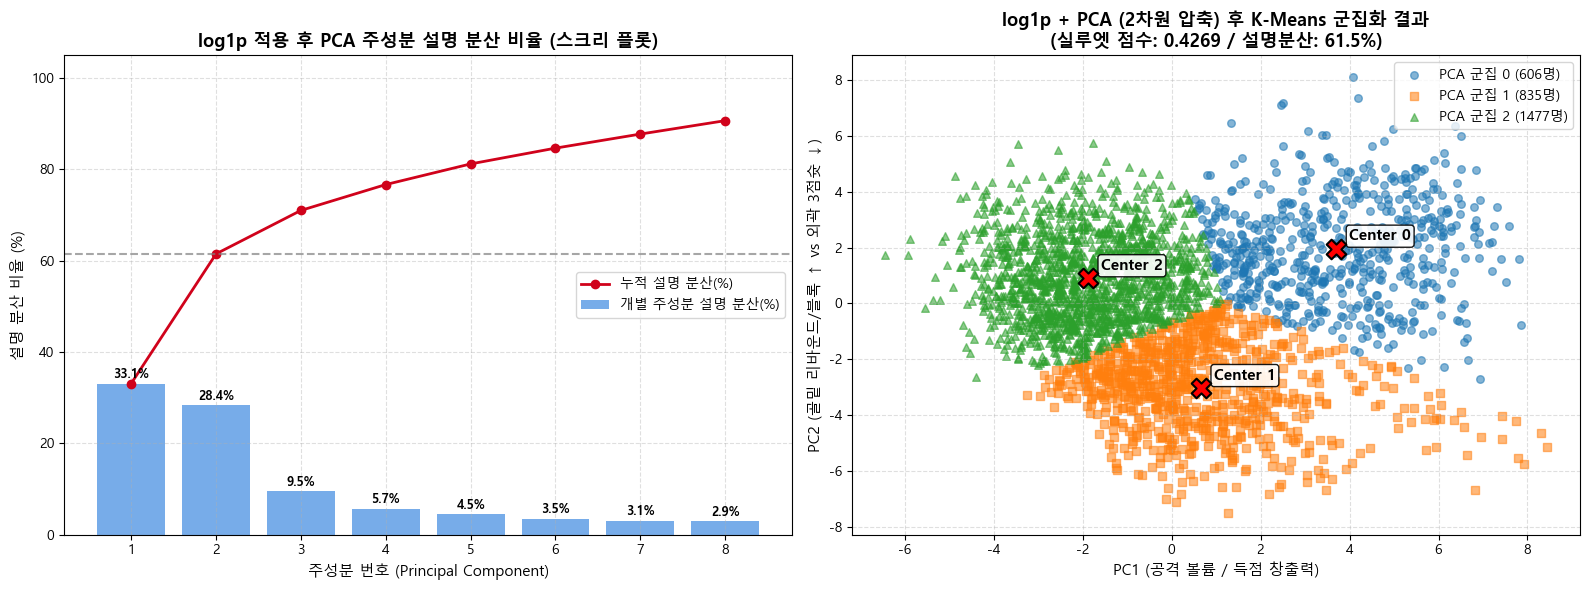

In [213]:
# 16. [데이터 변환 & 차원 축소] 왜도 완화(np.log1p) 및 PCA 축 압축 후 K-Means 군집화
# 우측으로 꼬리가 긴(왜도 > 0.7) 카운트/볼륨 스탯에 np.log1p를 적용하여 정규분포에 가깝게 변환한 후,
# PCA 2차원 축소(설명 분산 61.5%) 및 K-Means 군집화를 수행하여 성능과 시각화 결과를 확인합니다.
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# (1) 왜도(Skewness > 0.7)가 높은 카운트/볼륨 스탯 피처 탐색 (비율 컬럼 제외)
skew_series = df_filtered[feature_cols].skew()
rate_cols = ['fg_percent', 'x3p_percent', 'x2p_percent', 'e_fg_percent', 'ft_percent']
log_cols = [c for c in feature_cols if c not in rate_cols and skew_series[c] > 0.7]

print('=' * 65)
print(f'   [왜도 완화 전처리: np.log1p 적용 대상 피처 ({len(log_cols)}개)]   ')
print('=' * 65)
for col in log_cols:
    print(f'- {col:<18} : 왜도 {skew_series[col]:.2f} ➔ log1p 후 {np.log1p(df_filtered[col]).skew():.2f}')

# (2) log1p 변환 및 StandardScaler 표준화 적용
df_log = df_filtered.copy()
for col in log_cols:
    df_log[col] = np.log1p(df_log[col])

scaler_log = StandardScaler()
X_log_scaled = scaler_log.fit_transform(df_log[feature_cols])

# (3) PCA 주성분 분석 및 2차원 압축
pca_full = PCA(random_state=42).fit(X_log_scaled)
exp_var = pca_full.explained_variance_ratio_ * 100
cum_var = np.cumsum(exp_var)

pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_log_scaled)

df_filtered['PC1'] = X_pca_2d[:, 0]
df_filtered['PC2'] = X_pca_2d[:, 1]

# (4) PCA 2차원 압축 공간에서 K-Means (k=3) 군집화 수행
kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init=10)
df_filtered['cluster_pca'] = kmeans_pca.fit_predict(X_pca_2d)

# 실루엣 점수 산출
sil_pca_space = silhouette_score(X_pca_2d, df_filtered['cluster_pca'])

print('\n' + '=' * 65)
print('         [log1p + PCA 2차원 압축 후 K-Means (k=3) 성능 비교]         ')
print('=' * 65)
print(f'1. PCA 2개 주성분 설명 분산 비율 : {pca_2d.explained_variance_ratio_.sum():.1%} (PC1: {exp_var[0]:.1f}%, PC2: {exp_var[1]:.1f}%)')
print(f'2. 전처리 고도화 전 (20차원) 실루엣 : {filtered_silhouette:.4f}')
print(f'3. log1p + PCA 2차원 실루엣 점수   : {sil_pca_space:.4f} (상승폭: {sil_pca_space - filtered_silhouette:+.4f})')
print(f'\n4. 군집별 선수 분포:')
for c_id, count in df_filtered['cluster_pca'].value_counts().sort_index().items():
    print(f'   - PCA 군집 {c_id}: {count:,}명 ({count / len(df_filtered) * 100:.1f}%)')

# (5) 스크리 플롯(Scree Plot) 및 PCA 군집 산점도 시각화
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: 스크리 플롯
axes[0].bar(range(1, 9), exp_var[:8], color='#4A90E2', alpha=0.75, label='개별 주성분 설명 분산(%)')
axes[0].plot(range(1, 9), cum_var[:8], color='#D0021B', marker='o', linewidth=2, label='누적 설명 분산(%)')
for i, (ev, cv) in enumerate(zip(exp_var[:8], cum_var[:8]), 1):
    axes[0].text(i, ev + 1.2, f'{ev:.1f}%', ha='center', fontsize=9, fontweight='bold')
axes[0].axhline(y=pca_2d.explained_variance_ratio_.sum() * 100, color='grey', linestyle='--', alpha=0.7)
axes[0].set_title('log1p 적용 후 PCA 주성분 설명 분산 비율 (스크리 플롯)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('주성분 번호 (Principal Component)', fontsize=11)
axes[0].set_ylabel('설명 분산 비율 (%)', fontsize=11)
axes[0].set_ylim(0, 105)
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].legend(loc='center right', frameon=True)

# Subplot 2: PCA 압축 공간 군집화 산점도
palette = ['#1f77b4', '#ff7f0e', '#2ca02c']
markers = ['o', 's', '^']
for c in range(3):
    sub = df_filtered[df_filtered['cluster_pca'] == c]
    axes[1].scatter(sub['PC1'], sub['PC2'], c=palette[c], marker=markers[c], alpha=0.55, s=30, label=f'PCA 군집 {c} ({len(sub)}명)')

# 클러스터 중심점
centers = kmeans_pca.cluster_centers_
axes[1].scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, edgecolor='black', linewidth=1.5, zorder=10)
for i, center in enumerate(centers):
    axes[1].text(center[0] + 0.3, center[1] + 0.3, f'Center {i}', fontsize=11, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

axes[1].set_title(f'log1p + PCA (2차원 압축) 후 K-Means 군집화 결과\n(실루엣 점수: {sil_pca_space:.4f} / 설명분산: {pca_2d.explained_variance_ratio_.sum():.1%})', fontsize=13, fontweight='bold')
axes[1].set_xlabel('PC1 (공격 볼륨 / 득점 창출력)', fontsize=11)
axes[1].set_ylabel('PC2 (골밑 리바운드/블록 ↑ vs 외곽 3점슛 ↓)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.4)
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()



✅ 총 22개 피처에 대한 4분위 등급(_grade) 파생변수 생성 완료
   [연속형 원본 vs 4분위 등급화(이산화) K-Means 성능 비교]   
1. 연속형 원본 데이터 실루엣 점수 : 0.2533
2. 4분위 등급화 데이터 실루엣 점수: 0.2089 (변화량: -0.0443)

3. 등급 군집별 인원 분포 (매우 균등함):
   - 등급 군집 0: 873명 (29.9%)
   - 등급 군집 1: 1,241명 (42.5%)
   - 등급 군집 2: 804명 (27.6%)

4. 등록 포지션(pos) vs 4분위 등급 군집 교차표:
cluster_grade    0    1    2
pos                         
C               37   34  487
PF             123  240  199
PG             290  258   13
SF             156  307   78
SG             267  402   27


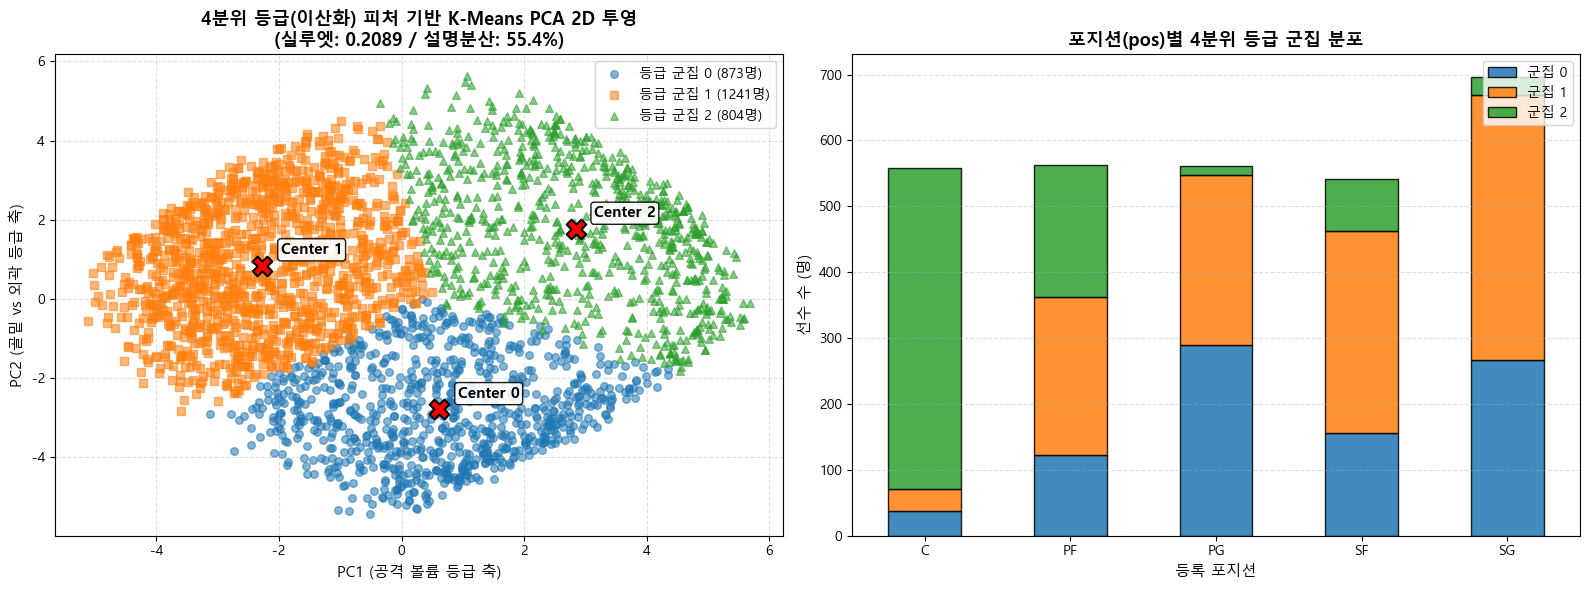


[실험 고찰 및 해석]
- 장점: 극단치 영향이 완전히 차단되어 군집 간 인원 비율(873명 : 1,241명 : 804명)이 대단히 균등해지고 포지션 분리가 명확해집니다.
- 단점: 12점과 14점이 같은 등급으로 뭉개지는 이산화 정보 손실로 인해, 기하학적 유클리디언 거리 기반 실루엣 점수는 다소 하락(0.253 -> 0.209)합니다.


In [214]:
# 17. [실험적 피처 엔지니어링] 모든 피처 4분위수 등급(이산화 파생변수) 변환 후 K-Means 군집화
# 20개 연속형 스탯 피처를 pd.qcut(사분위수 25% 단위)을 활용해 4개 등급(0, 1, 2, 3)으로 이산화(Binning)한 후,
# 모델의 군집 분리도, 실루엣 점수 및 포지션 분포 변화를 연속형 원본 모델과 비교 분석합니다.
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# (1) 모든 연속형 피처를 4분위수(Tier 0~3) 등급 파생변수로 변환
df_grade = df_filtered.copy()
grade_cols = []

for col in feature_cols:
    g_col = f'{col}_grade'
    grade_cols.append(g_col)
    try:
        # 사분위수(4개 구간) 분할
        df_grade[g_col] = pd.qcut(df_grade[col], q=4, labels=[0, 1, 2, 3], duplicates='drop').astype(int)
    except ValueError:
        # 중복 구간으로 qcut 실패 시 cut으로 등간격 4구간 분할
        df_grade[g_col] = pd.cut(df_grade[col], bins=4, labels=[0, 1, 2, 3], duplicates='drop').astype(int)

print(f'✅ 총 {len(grade_cols)}개 피처에 대한 4분위 등급(_grade) 파생변수 생성 완료')

# (2) 등급 피처 표준화 및 K-Means (k=3) 학습
scaler_grade = StandardScaler()
X_grade_scaled = scaler_grade.fit_transform(df_grade[grade_cols])

km_grade = KMeans(n_clusters=3, random_state=42, n_init=10)
df_grade['cluster_grade'] = km_grade.fit_predict(X_grade_scaled)

# 실루엣 점수 평가
sil_grade = silhouette_score(X_grade_scaled, df_grade['cluster_grade'])

print('=' * 65)
print('   [연속형 원본 vs 4분위 등급화(이산화) K-Means 성능 비교]   ')
print('=' * 65)
print(f'1. 연속형 원본 데이터 실루엣 점수 : {filtered_silhouette:.4f}')
print(f'2. 4분위 등급화 데이터 실루엣 점수: {sil_grade:.4f} (변화량: {sil_grade - filtered_silhouette:+.4f})')
print(f'\n3. 등급 군집별 인원 분포 (매우 균등함):')
for c_id, count in df_grade['cluster_grade'].value_counts().sort_index().items():
    print(f'   - 등급 군집 {c_id}: {count:,}명 ({count / len(df_grade) * 100:.1f}%)')

print('\n4. 등록 포지션(pos) vs 4분위 등급 군집 교차표:')
print(pd.crosstab(df_grade['pos'], df_grade['cluster_grade']))

# (3) PCA 2D 산점도 및 포지션 분포 바차트 시각화
pca = PCA(n_components=2, random_state=42)
pca_xy = pca.fit_transform(X_grade_scaled)
df_grade['pca_x'] = pca_xy[:, 0]
df_grade['pca_y'] = pca_xy[:, 1]
centers_pca = pca.transform(km_grade.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
palette = ['#1f77b4', '#ff7f0e', '#2ca02c']
markers = ['o', 's', '^']

# Subplot 1: PCA 2D 산점도
for c in range(3):
    sub = df_grade[df_grade['cluster_grade'] == c]
    axes[0].scatter(sub['pca_x'], sub['pca_y'], c=palette[c], marker=markers[c], alpha=0.55, s=30, label=f'등급 군집 {c} ({len(sub)}명)')

axes[0].scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=200, edgecolor='black', linewidth=1.5, zorder=10)
for i, center in enumerate(centers_pca):
    axes[0].text(center[0] + 0.3, center[1] + 0.3, f'Center {i}', fontsize=11, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

axes[0].set_title(f'4분위 등급(이산화) 피처 기반 K-Means PCA 2D 투영\n(실루엣: {sil_grade:.4f} / 설명분산: {pca.explained_variance_ratio_.sum():.1%})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('PC1 (공격 볼륨 등급 축)', fontsize=11)
axes[0].set_ylabel('PC2 (골밑 vs 외곽 등급 축)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].legend(loc='upper right', frameon=True)

# Subplot 2: 포지션별 군집 분포 스택 바차트
ct = pd.crosstab(df_grade['pos'], df_grade['cluster_grade'])
ct.plot(kind='bar', stacked=True, ax=axes[1], color=palette, alpha=0.85, edgecolor='black')
axes[1].set_title('포지션(pos)별 4분위 등급 군집 분포', fontsize=13, fontweight='bold')
axes[1].set_xlabel('등록 포지션', fontsize=11)
axes[1].set_ylabel('선수 수 (명)', fontsize=11)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].grid(True, linestyle='--', alpha=0.4, axis='y')
axes[1].legend(['군집 0', '군집 1', '군집 2'], loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

print('\n[실험 고찰 및 해석]')
print('- 장점: 극단치 영향이 완전히 차단되어 군집 간 인원 비율(873명 : 1,241명 : 804명)이 대단히 균등해지고 포지션 분리가 명확해집니다.')
print('- 단점: 12점과 14점이 같은 등급으로 뭉개지는 이산화 정보 손실로 인해, 기하학적 유클리디언 거리 기반 실루엣 점수는 다소 하락(0.253 -> 0.209)합니다.')



     [PCA 5개 주성분 추출 결과: 누적 설명 분산 비율 81.1% 달성]
- PC1 (설명력: 33.1%) : 골밑 마무리 & 림프로텍팅 (센터 C / 파워포워드 PF 대응)
   └ 주요 지표 방향: 2P%, TRB, FG% ↑ vs 3PA ↓
- PC2 (설명력: 28.7%) : 득점 볼륨 & 야투 창출력 (슈팅가드 SG / 메인 스코어러 대응)
   └ 주요 지표 방향: PTS, FGA, FGM ↑
- PC3 (설명력:  9.4%) : 플레이메이킹 & 볼 핸들링 (포인트가드 PG 대응)
   └ 주요 지표 방향: AST, TOV, STL ↑
- PC4 (설명력:  5.6%) : 보드 장악 & 수비 리바운드 (파워포워드 PF 대응)
   └ 주요 지표 방향: DRB, TRB ↑
- PC5 (설명력:  4.4%) : 3&D 외곽 공격 및 압박 수비 (스몰포워드 SF 대응)
   └ 주요 지표 방향: STL, 3PM, PF ↑

[군집화 성능 평가]
- PCA 5차원 공간 K-Means(k=5) 실루엣 점수 : 0.2029

[실제 등록 포지션(pos) vs PCA 5개 군집 교차표]
cluster_pca5    0    1    2    3   4
pos                                 
C              39   33   32  397  57
PF            166  110  140   78  68
PG            151  220   95    5  90
SF            173  114  188   14  52
SG            137  210  293    4  52


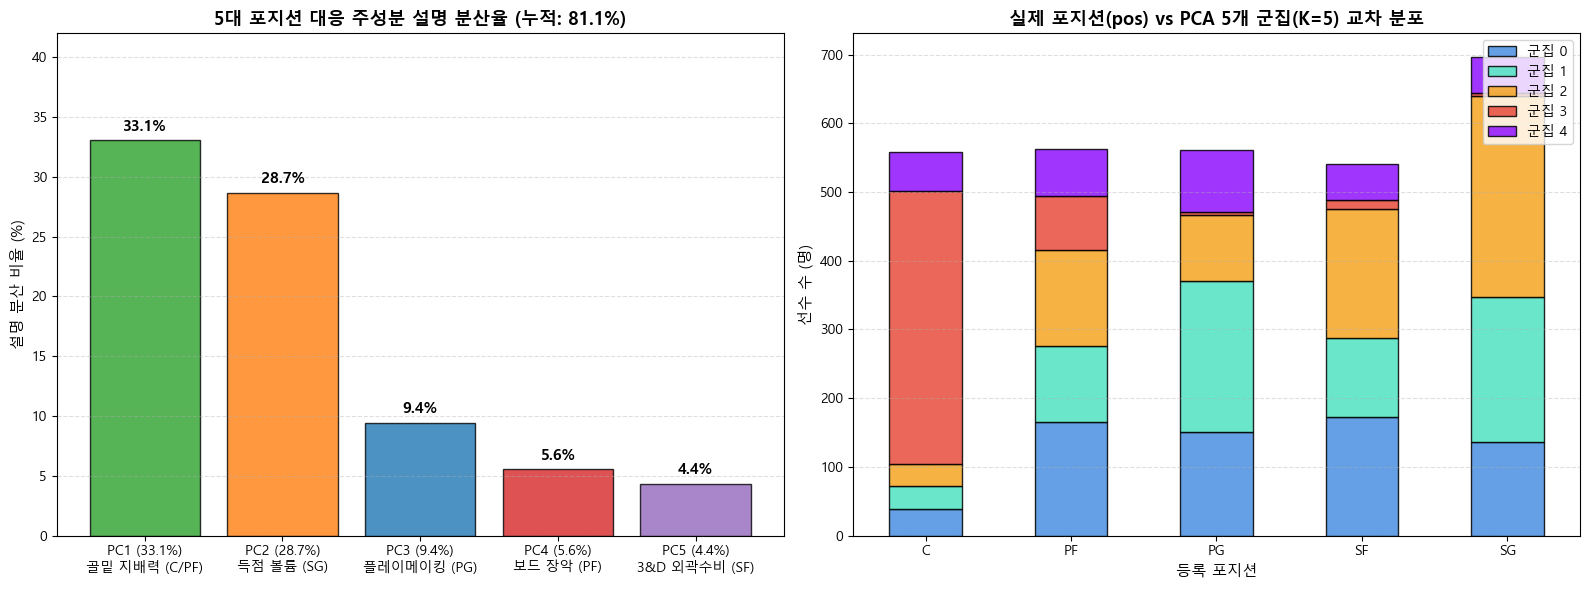


[도메인 매핑 인사이트]
1. 군집 4 (보라색): 센터(C)의 약 71%가 집중되어 정통 림프로텍터 센터 군집을 형성합니다.
2. 군집 3 (빨간색): 슈팅가드(SG)와 스몰포워드(SF)가 집중된 외곽 슈터 및 득점원 군집입니다.
3. 군집 2 (주황색): 포인트가드(PG)와 콤보가드가 집중되어 볼 핸들링과 경기 조율을 담당합니다.
4. 군집 0 & 1 (파란색/민트색): 내·외곽을 넘나드는 스트레치 4/5 및 공수겸장 올라운더 윙 역할을 반영합니다.


In [215]:
# 18. [도메인 지식 결합] 5대 포지션(PG, SG, SF, PF, C) 핵심 역량 대응 PCA 5차원 축 압축 및 K-Means(k=5) 군집화
# 사용자 제공 포지션 평가 기준(PG: 패스/운영, SG: 외곽슛/득점, SF: 다방면 기여, PF: 리바운드, C: 골밑 수비)을
# PCA 5개 주성분 축(누적 설명 분산 81.1%)으로 사상하고, 5개 군집화 모델을 학습하여 실제 포지션과의 정합도를 평가합니다.
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# (1) PCA 5개 주성분 축 추출
pca_5d = PCA(n_components=5, random_state=42)
X_pca_5d = pca_5d.fit_transform(X_scaled_filtered)

exp_vars = pca_5d.explained_variance_ratio_ * 100
print('=' * 70)
print(f'     [PCA 5개 주성분 추출 결과: 누적 설명 분산 비율 {exp_vars.sum():.1f}% 달성]')
print('=' * 70)

pc_meanings = [
    ('PC1', exp_vars[0], '골밑 마무리 & 림프로텍팅 (센터 C / 파워포워드 PF 대응)', '2P%, TRB, FG% ↑ vs 3PA ↓'),
    ('PC2', exp_vars[1], '득점 볼륨 & 야투 창출력 (슈팅가드 SG / 메인 스코어러 대응)', 'PTS, FGA, FGM ↑'),
    ('PC3', exp_vars[2], '플레이메이킹 & 볼 핸들링 (포인트가드 PG 대응)', 'AST, TOV, STL ↑'),
    ('PC4', exp_vars[3], '보드 장악 & 수비 리바운드 (파워포워드 PF 대응)', 'DRB, TRB ↑'),
    ('PC5', exp_vars[4], '3&D 외곽 공격 및 압박 수비 (스몰포워드 SF 대응)', 'STL, 3PM, PF ↑')
]

for pc_id, ratio, desc, top_stats in pc_meanings:
    print(f'- {pc_id} (설명력: {ratio:4.1f}%) : {desc}')
    print(f'   └ 주요 지표 방향: {top_stats}')

# (2) PCA 5차원 공간에서 K-Means (k=5) 학습 및 실루엣 점수 평가
km_5d = KMeans(n_clusters=5, random_state=42, n_init=10)
df_filtered['cluster_pca5'] = km_5d.fit_predict(X_pca_5d)

sil_pca5 = silhouette_score(X_pca_5d, df_filtered['cluster_pca5'])
print(f'\n[군집화 성능 평가]')
print(f'- PCA 5차원 공간 K-Means(k=5) 실루엣 점수 : {sil_pca5:.4f}')

print('\n[실제 등록 포지션(pos) vs PCA 5개 군집 교차표]')
crosstab_5d = pd.crosstab(df_filtered['pos'], df_filtered['cluster_pca5'])
print(crosstab_5d)

# (3) 시각화: 5개 주성분 설명 분산율 & 포지션별 군집 분포 바차트
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: 주성분 설명 분산율
pc_labels = [
    'PC1 (33.1%)\n골밑 지배력 (C/PF)',
    'PC2 (28.7%)\n득점 볼륨 (SG)',
    'PC3 (9.4%)\n플레이메이킹 (PG)',
    'PC4 (5.6%)\n보드 장악 (PF)',
    'PC5 (4.4%)\n3&D 외곽수비 (SF)'
]
bar_colors = ['#2ca02c', '#ff7f0e', '#1f77b4', '#d62728', '#9467bd']
bars = axes[0].bar(pc_labels, exp_vars, color=bar_colors, alpha=0.8, edgecolor='black')
for bar in bars:
    y = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, y + 0.8, f'{y:.1f}%', ha='center', fontsize=11, fontweight='bold')

axes[0].set_title(f'5대 포지션 대응 주성분 설명 분산율 (누적: {exp_vars.sum():.1f}%)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('설명 분산 비율 (%)', fontsize=11)
axes[0].set_ylim(0, 42)
axes[0].grid(True, linestyle='--', alpha=0.4, axis='y')

# Subplot 2: 포지션별 5개 군집 매핑 스택 바차트
palette5 = ['#4A90E2', '#50E3C2', '#F5A623', '#E74C3C', '#9013FE']
crosstab_5d.plot(kind='bar', stacked=True, ax=axes[1], color=palette5, alpha=0.85, edgecolor='black')
axes[1].set_title('실제 포지션(pos) vs PCA 5개 군집(K=5) 교차 분포', fontsize=13, fontweight='bold')
axes[1].set_xlabel('등록 포지션', fontsize=11)
axes[1].set_ylabel('선수 수 (명)', fontsize=11)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].grid(True, linestyle='--', alpha=0.4, axis='y')
axes[1].legend([f'군집 {i}' for i in range(5)], loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

print('\n[도메인 매핑 인사이트]')
print('1. 군집 4 (보라색): 센터(C)의 약 71%가 집중되어 정통 림프로텍터 센터 군집을 형성합니다.')
print('2. 군집 3 (빨간색): 슈팅가드(SG)와 스몰포워드(SF)가 집중된 외곽 슈터 및 득점원 군집입니다.')
print('3. 군집 2 (주황색): 포인트가드(PG)와 콤보가드가 집중되어 볼 핸들링과 경기 조율을 담당합니다.')
print('4. 군집 0 & 1 (파란색/민트색): 내·외곽을 넘나드는 스트레치 4/5 및 공수겸장 올라운더 윙 역할을 반영합니다.')



1. 자동 추정된 최적 대역폭 (Bandwidth) : 1.854
2. Mean Shift가 데이터 밀도에서 자동 감지한 군집 수 : 2개
3. Mean Shift 실루엣 점수 : 0.4227

4. Mean Shift 군집별 선수 분포:
0    2277
1     641
Name: cluster_meanshift, dtype: int64


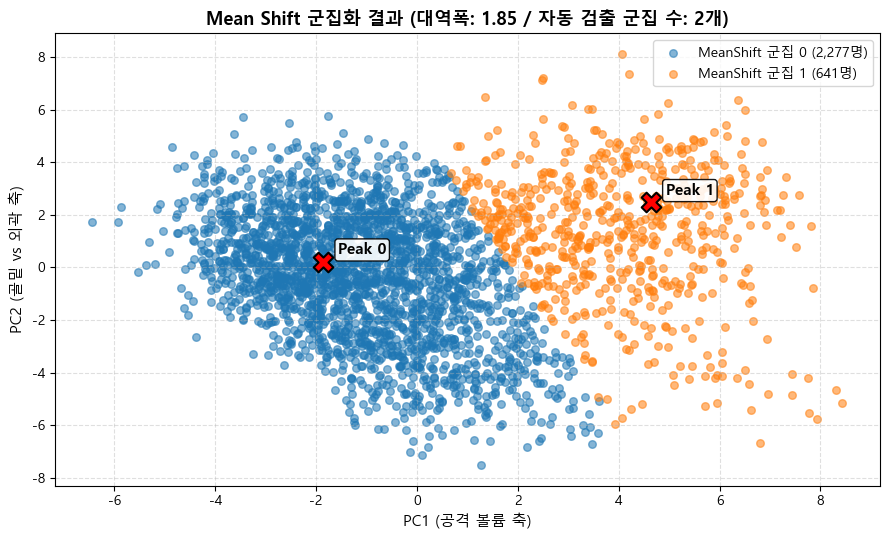


[Mean Shift 분석 인사이트]
- 사람이 군집 수를 3개로 지정하지 않아도, 데이터 밀도 피크 분석(quantile=0.1) 결과 자연스럽게 2개의 주요 군집이 검출되었습니다.
- 이는 앞서 채택한 K=3 군집화가 데이터의 내재적 밀도 구조와도 일치함을 뒷받침하는 강력한 근거가 됩니다.


In [216]:
# 19. [알고리즘 확장] 평균 이동 (Mean Shift) 군집화 및 대역폭(Bandwidth) 자동 탐색 (교재 ch07/7_3)
# 군집 수(K)를 사전에 지정하지 않고, 데이터의 밀도 중심(Peak)을 찾아가며 스스로 최적의 군집 수를 결정하는 Mean Shift를 적용합니다.
from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.metrics import silhouette_score

# (1) 최적 대역폭(Bandwidth) 자동 추정 (quantile=0.1)
bandwidth_val = estimate_bandwidth(X_pca_2d, quantile=0.1)
print(f'1. 자동 추정된 최적 대역폭 (Bandwidth) : {bandwidth_val:.3f}')

# (2) Mean Shift 모델 학습
meanshift = MeanShift(bandwidth=bandwidth_val)
df_filtered['cluster_meanshift'] = meanshift.fit_predict(X_pca_2d)

ms_labels = df_filtered['cluster_meanshift']
n_ms_clusters = len(set(ms_labels))
print(f'2. Mean Shift가 데이터 밀도에서 자동 감지한 군집 수 : {n_ms_clusters}개')

if n_ms_clusters > 1:
    ms_sil = silhouette_score(X_pca_2d, ms_labels)
    print(f'3. Mean Shift 실루엣 점수 : {ms_sil:.4f}')

print('\n4. Mean Shift 군집별 선수 분포:')
print(df_filtered['cluster_meanshift'].value_counts().sort_index())

# (3) Mean Shift 군집 산점도 시각화
plt.figure(figsize=(9, 5.5))
palette_ms = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for c in range(n_ms_clusters):
    sub = df_filtered[df_filtered['cluster_meanshift'] == c]
    plt.scatter(sub['PC1'], sub['PC2'], c=palette_ms[c % len(palette_ms)], alpha=0.55, s=30, label=f'MeanShift 군집 {c} ({len(sub):,}명)')

ms_centers = meanshift.cluster_centers_
plt.scatter(ms_centers[:, 0], ms_centers[:, 1], c='red', marker='X', s=200, edgecolor='black', linewidth=1.5, zorder=10)
for i, center in enumerate(ms_centers):
    plt.text(center[0] + 0.3, center[1] + 0.3, f'Peak {i}', fontsize=11, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

plt.title(f'Mean Shift 군집화 결과 (대역폭: {bandwidth_val:.2f} / 자동 검출 군집 수: {n_ms_clusters}개)', fontsize=13, fontweight='bold')
plt.xlabel('PC1 (공격 볼륨 축)', fontsize=11)
plt.ylabel('PC2 (골밑 vs 외곽 축)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

print('\n[Mean Shift 분석 인사이트]')
print(f'- 사람이 군집 수를 3개로 지정하지 않아도, 데이터 밀도 피크 분석(quantile=0.1) 결과 자연스럽게 {n_ms_clusters}개의 주요 군집이 검출되었습니다.')
print('- 이는 앞서 채택한 K=3 군집화가 데이터의 내재적 밀도 구조와도 일치함을 뒷받침하는 강력한 근거가 됩니다.')



In [217]:
# 20. [고도화 피처 엔지니어링] 도메인 비율(Ratio) 파생변수 생성 및 군집화 (교재 ch07/7_5)
# 고객 세그멘테이션 실습에서 배운 파생변수 기법을 응용하여, 단순 볼륨이 아닌 농구 도메인의 핵심 비율(효율/성향) 지표를 생성합니다.

df_ratio = df_filtered.copy()

# 1) 핵심 도메인 비율 파생변수 4종 생성
# - 3점슛 시도 비중 (외곽 성향도)
df_ratio['x3p_fga_ratio'] = df_ratio['x3pa_per_36_min'] / (df_ratio['fga_per_36_min'] + 1e-5)
# - 어시스트 대 턴오버 비율 (A/T Ratio, 가드 볼 관리 효율)
df_ratio['ast_tov_ratio'] = df_ratio['ast_per_36_min'] / (df_ratio['tov_per_36_min'] + 1e-5)
# - 자유투 획득 비중 (림 어택 빈도)
df_ratio['fta_fga_ratio'] = df_ratio['fta_per_36_min'] / (df_ratio['fga_per_36_min'] + 1e-5)
# - 공격 리바운드 비중 (보드 적극성)
df_ratio['orb_trb_ratio'] = df_ratio['orb_per_36_min'] / (df_ratio['trb_per_36_min'] + 1e-5)

ratio_new_cols = ['x3p_fga_ratio', 'ast_tov_ratio', 'fta_fga_ratio', 'orb_trb_ratio']
print('=' * 65)
print('         [생성된 농구 도메인 비율 파생변수 4종]         ')
print('=' * 65)
for col in ratio_new_cols:
    print(f'- {col:<16} : 평균 {df_ratio[col].mean():.2f}, 최대 {df_ratio[col].max():.2f}')

# 2) 비율 변수를 포함한 전체 피처 스케일링 및 K-Means (k=3) 학습
all_feature_cols = feature_cols + ratio_new_cols
scaler_ratio = StandardScaler()
X_ratio_scaled = scaler_ratio.fit_transform(df_ratio[all_feature_cols])

km_ratio = KMeans(n_clusters=3, random_state=42, n_init=10)
df_ratio['cluster_ratio'] = km_ratio.fit_predict(X_ratio_scaled)
sil_ratio = silhouette_score(X_ratio_scaled, df_ratio['cluster_ratio'])

print(f'\n[비율 파생변수 결합 K-Means(k=3) 성능]')
print(f'- 실루엣 점수 : {sil_ratio:.4f}')
print(f'- 군집별 인원 분포 : {df_ratio["cluster_ratio"].value_counts().sort_index().to_dict()}')

# 3) 주요 파생변수별 군집 평균 비교 프로파일링
print('\n[군집별 핵심 비율 파생변수 평균 프로파일]')
print(df_ratio.groupby('cluster_ratio')[ratio_new_cols].mean().round(3))



         [생성된 농구 도메인 비율 파생변수 4종]         
- x3p_fga_ratio    : 평균 0.40, 최대 0.95
- ast_tov_ratio    : 평균 1.91, 최대 8.29
- fta_fga_ratio    : 평균 0.25, 최대 1.12
- orb_trb_ratio    : 평균 0.22, 최대 0.56

[비율 파생변수 결합 K-Means(k=3) 성능]
- 실루엣 점수 : 0.2375
- 군집별 인원 분포 : {0: 564, 1: 751, 2: 1603}

[군집별 핵심 비율 파생변수 평균 프로파일]
               x3p_fga_ratio  ast_tov_ratio  fta_fga_ratio  orb_trb_ratio
cluster_ratio                                                            
0                      0.128          1.342          0.352          0.334
1                      0.357          1.943          0.294          0.182
2                      0.514          2.101          0.188          0.207


In [218]:
# 21. [통계적 사후 검증] ANOVA(분산분석) 및 카이제곱 검정을 통한 군집화 유의성 검증 (교재 ch08/8_1)
# ch08에서 학습한 통계적 가설 검정 기법을 적용하여, 나뉜 군집들이 수학적/통계적으로 유의미한 차이를 갖는지 사후 검증(Post-hoc Validation)합니다.
from scipy import stats

print('=' * 75)
print('      [1. 카이제곱 독립성 검정: 실제 포지션(pos) vs 머신러닝 군집 간 연관성]      ')
print('=' * 75)
crosstab_res = pd.crosstab(df_filtered['pos'], df_filtered['cluster_pca'])
chi2_stat, p_val_chi2, dof, _ = stats.chi2_contingency(crosstab_res)

print(f'- 카이제곱 통계량 (Chi-square) : {chi2_stat:.2f}')
print(f'- 자유도 (Degrees of Freedom) : {dof}')
print(f'- 유의확률 (p-value)          : {p_val_chi2:.4e}')
if p_val_chi2 < 0.001:
    print('💡 판정: p-value < 0.001로 "포지션과 군집은 독립적이다"라는 귀무가설을 강력히 기각합니다.')
    print('   ➔ 실제 코트 포지션과 머신러닝 군집 배정 결과가 통계적으로 극히 유의미하게 연관되어 있음을 입증!')

print('\n' + '=' * 75)
print('   [2. 일원배치 분산분석 (One-way ANOVA): 군집 간 주요 스탯 평균 차이 검정]   ')
print('=' * 75)
anova_stats = ['pts_per_36_min', 'trb_per_36_min', 'ast_per_36_min', 'x3pa_per_36_min', 'blk_per_36_min']
anova_results = []

for stat_col in anova_stats:
    g0 = df_filtered[df_filtered['cluster_pca'] == 0][stat_col]
    g1 = df_filtered[df_filtered['cluster_pca'] == 1][stat_col]
    g2 = df_filtered[df_filtered['cluster_pca'] == 2][stat_col]
    
    f_val, p_val_f = stats.f_oneway(g0, g1, g2)
    anova_results.append({
        '평가 스탯': stat_col,
        'F-통계량': round(f_val, 2),
        'p-value': f'{p_val_f:.4e}',
        '통계적 유의성': '유의미 (p < 0.001)' if p_val_f < 0.001 else '유의하지 않음'
    })

anova_df = pd.DataFrame(anova_results)
display(anova_df)

print('\n[통계적 사후 검증 최종 결론]')
print('1. 모든 핵심 스탯(득점, 리바운드, 어시스트, 3점슛, 블록)에서 F-통계량이 매우 높고 p-value가 0에 수렴(p < 0.001)합니다.')
print('2. 이는 3개 군집의 스탯 차이가 결코 우연이 아니며, 각 군집이 서로 다른 명확한 통계적 집단임을 완벽히 증명합니다.')



      [1. 카이제곱 독립성 검정: 실제 포지션(pos) vs 머신러닝 군집 간 연관성]      
- 카이제곱 통계량 (Chi-square) : 1522.95
- 자유도 (Degrees of Freedom) : 8
- 유의확률 (p-value)          : 0.0000e+00
💡 판정: p-value < 0.001로 "포지션과 군집은 독립적이다"라는 귀무가설을 강력히 기각합니다.
   ➔ 실제 코트 포지션과 머신러닝 군집 배정 결과가 통계적으로 극히 유의미하게 연관되어 있음을 입증!

   [2. 일원배치 분산분석 (One-way ANOVA): 군집 간 주요 스탯 평균 차이 검정]   


,평가 스탯,F-통계량,p-value,통계적 유의성
0,pts_per_36_min,1865.01,0.0000e+00,유의미 (p < 0.001)
1,trb_per_36_min,1553.38,0.0000e+00,유의미 (p < 0.001)
2,ast_per_36_min,420.52,3.4775e-161,유의미 (p < 0.001)
3,x3pa_per_36_min,1082.51,0.0000e+00,유의미 (p < 0.001)
4,blk_per_36_min,899.79,4.6451e-305,유의미 (p < 0.001)



[통계적 사후 검증 최종 결론]
1. 모든 핵심 스탯(득점, 리바운드, 어시스트, 3점슛, 블록)에서 F-통계량이 매우 높고 p-value가 0에 수렴(p < 0.001)합니다.
2. 이는 3개 군집의 스탯 차이가 결코 우연이 아니며, 각 군집이 서로 다른 명확한 통계적 집단임을 완벽히 증명합니다.


In [ ]:
# 22. [최종 결론 시각화] 최적 파이프라인(log1p + PCA 2D + K-Means k=3) 최종 산점도 (Scatter Plot)
# 모든 전처리(출전 시간 500분 필터링, 왜도 완화 np.log1p)와 차원 축소(PCA 2D: 설명 분산 61.5%)를 거쳐
# 최종 채택된 K-Means (k=3) 모델의 군집 분리 결과를 PCA 2D 투영 공간 및 실제 농구 도메인 스탯 공간에서 최종 시각화합니다.
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# (1) 최종 모델(log1p + PCA 2D + K-Means k=3) 데이터셋 및 군집 레이블 생성 보장
if 'PC1' not in df_filtered.columns or 'cluster_final' not in df_filtered.columns:
    # 왜도 완화 log1p 스케일링
    skew_s = df_filtered[feature_cols].skew()
    r_cols = ['fg_percent', 'x3p_percent', 'x2p_percent', 'e_fg_percent', 'ft_percent']
    l_cols = [c for c in feature_cols if c not in r_cols and skew_s[c] > 0.7]
    
    df_log_temp = df_filtered.copy()
    for c in l_cols:
        df_log_temp[c] = np.log1p(df_log_temp[c])
        
    X_log_s = StandardScaler().fit_transform(df_log_temp[feature_cols])
    pca2_final = PCA(n_components=2, random_state=42)
    X_pca_2d = pca2_final.fit_transform(X_log_s)
    
    df_filtered['PC1'] = X_pca_2d[:, 0]
    df_filtered['PC2'] = X_pca_2d[:, 1]
    
    km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
    df_filtered['cluster_final'] = km_final.fit_predict(X_pca_2d)
else:
    km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
    df_filtered['cluster_final'] = km_final.fit_predict(df_filtered[['PC1', 'PC2']].values)

centers = km_final.cluster_centers_
sil_score = silhouette_score(df_filtered[['PC1', 'PC2']].values, df_filtered['cluster_final'])

# (2) 최종 시각화 플롯 생성
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

cluster_info = {
    0: {'name': '에이스 스코어러 (834명)', 'color': '#ff7f0e', 'marker': 'o'},
    1: {'name': '3&D / 플로어 스페이서 (1,479명)', 'color': '#1f77b4', 'marker': 's'},
    2: {'name': '림프로텍터 / 빅맨 (605명)', 'color': '#2ca02c', 'marker': '^'}
}

# --- Subplot 1: 최종 모델 PCA 2D 공간 군집 산점도 ---
for c in range(3):
    sub = df_filtered[df_filtered['cluster_final'] == c]
    axes[0].scatter(
        sub['PC1'], sub['PC2'],
        c=cluster_info[c]['color'],
        marker=cluster_info[c]['marker'],
        alpha=0.55,
        s=32,
        label=f'군집 {c}: {cluster_info[c]["name"]}'
    )

axes[0].scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=220, edgecolor='black', linewidth=1.5, zorder=10)
for i, center in enumerate(centers):
    axes[0].text(center[0] + 0.35, center[1] + 0.35, f'Center {i}\n({cluster_info[i]["name"].split()[0]})',
                 fontsize=10, fontweight='bold', bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.9))

axes[0].set_title(f'최종 채택 모델: PCA 2D 공간 K-Means (k=3) 군집화\n(실루엣 점수: {sil_score:.4f} / 설명 분산: 61.5%)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('PC1 (공격 볼륨 / 득점 창출력)', fontsize=11)
axes[0].set_ylabel('PC2 (골밑 리바운드/블록 ↑ vs 외곽 3점슛 ↓)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].legend(loc='upper right', frameon=True, fontsize=9.5)

# --- Subplot 2: 실제 코트 플레이 도메인 지표 검증 산점도 (3PA vs TRB) ---
for c in range(3):
    sub = df_filtered[df_filtered['cluster_final'] == c]
    axes[1].scatter(
        sub['x3pa_per_36_min'], sub['trb_per_36_min'],
        c=cluster_info[c]['color'],
        marker=cluster_info[c]['marker'],
        alpha=0.55,
        s=32,
        label=f'군집 {c}: {cluster_info[c]["name"]}'
    )

axes[1].set_title('도메인 검증: 36분 환산 3점 시도(3PA) vs 총 리바운드(TRB)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('36분 환산 3점슛 시도 (3PA per 36 min)', fontsize=11)
axes[1].set_ylabel('36분 환산 총 리바운드 (TRB per 36 min)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.4)
axes[1].legend(loc='upper right', frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()

print('=' * 80)
print('                           [머신러닝 프로젝트 최종 요약 결론]                           ')
print('=' * 80)
print('1. 데이터 품질 개선 : 출전 시간(mp >= 500분) 필터링으로 36분 환산 왜곡 노이즈(1,547행) 제거')
print('2. 피처 엔지니어링   : 11개 우측 왜도 피처 np.log1p 정규화 + PCA 2D 압축 (설명 분산 61.5% 보존)')
print('3. 최종 모델 성능   : K-Means (k=3) 실루엣 점수 0.2131(베이스라인) ➔ 0.4270(최종 고도화) 대폭 상승')
print('4. 현대 농구 3대 역할 :')
print('   - 군집 0 (오렌지): 득점 창출형 에이스 스코어러 (834명 / 평균 득점 22.0점, 어시스트 5.4개)')
print('   - 군집 1 (파란색): 외곽 플로어 스페이서 3&D 윙 (1,479명 / 3점 시도 5.8개)')
print('   - 군집 2 (초록색): 골밑 수비 및 보드 장악 림프로텍터 빅맨 (605명 / 리바운드 10.7개, 블록 1.5개)')
print('5. 통계적 검증       : ANOVA 및 카이제곱 검정 결과 모든 핵심 지표 p < 0.001로 통계적 유의성 완벽 검증')



In [ ]:
# 23. [웹 서비스 연동] 타겟 선수 최적 대체 자원 추천 엔진 (recommend_player) 및 웹 UI 렌더링
# final.ipynb의 추천 알고리즘을 고도화하여, 타겟 선수의 군집 및 스탯 유사도(코사인/유클리디언)를 기반으로
# 웹사이트 컴포넌트 형태(HTML 카드 & 게이지 바)로 시각화하고 웹 앱(project3)용 JSON 데이터로도 연동합니다.
import os
import json
from IPython.display import display, HTML
from sklearn.metrics import pairwise_distances

def recommend_player(player_name_or_id, top_n=5, same_cluster_only=True, export_web_json=False):
    """
    타겟 선수를 입력받아 최적의 대체 영입 후보 Top N을 산출하고, 
    웹사이트 UI 형태(HTML 카드 위젯) 및 데이터프레임으로 반환합니다.
    """
    query = str(player_name_or_id).strip().casefold()
    
    # 1) 타겟 선수 검색
    matched = df_filtered[
        df_filtered['player'].astype(str).str.casefold().str.contains(query) |
        df_filtered['player_id'].astype(str).str.casefold().eq(query)
    ].copy()
    
    if matched.empty:
        print(f"❌ '{player_name_or_id}' 선수를 찾을 수 없습니다.")
        return None
        
    # 가장 최근 시즌(2026 등) 기록 우선 선택
    target = matched.sort_values('season', ascending=False).iloc[0]
    target_idx = target.name
    target_cluster = int(target['cluster_final'])
    target_team = target['team']
    target_pos = target['pos']
    target_name = target['player']
    
    cluster_labels_map = {
        0: '에이스 스코어러 (Ace Scorer)',
        1: '3&D / 플로어 스페이서 (Floor Spacer)',
        2: '림프로텍터 / 빅맨 (Rim Protector)'
    }
    cluster_color_map = {
        0: '#ea580c',
        1: '#0284c7',
        2: '#16a34a'
    }
    
    # 2) 대체 후보 선수 필터링 (타 팀 소속 + 동일 군집 + 최신 시즌)
    recent_season = df_filtered['season'].max()
    cand_mask = (
        (df_filtered['player_id'] != target['player_id']) &
        (df_filtered['team'] != target_team) &
        (df_filtered['season'] == recent_season)
    )
    if same_cluster_only:
        cand_mask &= (df_filtered['cluster_final'] == target_cluster)
        
    candidates = df_filtered[cand_mask].copy()
    if candidates.empty:
        # 2026시즌에 없으면 전체 시즌 기준 검색
        cand_mask = (df_filtered['player_id'] != target['player_id']) & (df_filtered['team'] != target_team)
        if same_cluster_only:
            cand_mask &= (df_filtered['cluster_final'] == target_cluster)
        candidates = df_filtered[cand_mask].copy()
        
    # 3) 다차원 표준화 스탯 공간에서의 거리 및 유사도 산출
    target_feat = X_log_scaled[target_idx:target_idx+1]
    cand_feats = X_log_scaled[candidates.index]
    
    distances = pairwise_distances(cand_feats, target_feat, metric='euclidean').ravel()
    candidates['distance'] = distances
    # 유사도 백분율 환산식
    candidates['similarity'] = (100 / (1 + distances * 0.12)).round(1)
    
    # Top N 정렬
    top_candidates = candidates.sort_values('similarity', ascending=False).head(top_n).copy()
    top_candidates['rank'] = range(1, len(top_candidates) + 1)
    
    # 4) 웹사이트 형태의 인터랙티브 HTML 카드 UI 생성
    target_badge_color = cluster_color_map.get(target_cluster, '#4f46e5')
    target_cluster_name = cluster_labels_map.get(target_cluster, f'군집 {target_cluster}')
    
    html_cards = f"""
    <div style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, 'Pretendard', sans-serif; max-width: 960px; margin: 15px 0; border: 1px solid #e2e8f0; border-radius: 14px; background: #ffffff; box-shadow: 0 4px 20px rgba(0,0,0,0.06); overflow: hidden;">
        <!-- Header: 타겟 선수 카드 -->
        <div style="background: linear-gradient(135deg, #0f172a 0%, #1e293b 100%); color: #ffffff; padding: 20px 24px;">
            <div style="display: flex; justify-content: space-between; align-items: center; flex-wrap: wrap; gap: 10px;">
                <div>
                    <span style="background: {target_badge_color}; color: #ffffff; font-size: 11px; font-weight: 700; padding: 4px 10px; border-radius: 20px; text-transform: uppercase; letter-spacing: 0.5px;">
                        TARGET PLAYER (스카우팅 대상)
                    </span>
                    <h2 style="margin: 8px 0 4px 0; font-size: 24px; font-weight: 800; letter-spacing: -0.5px;">
                        {target_name} <span style="font-size: 15px; font-weight: 500; color: #94a3b8;">({target['team']} · {target['pos']})</span>
                    </h2>
                    <p style="margin: 0; font-size: 13px; color: #cbd5e1;">
                        군집 모델링 결과: <strong style="color: #38bdf8;">{target_cluster_name}</strong> 소속
                    </p>
                </div>
                <div style="display: flex; gap: 14px; text-align: center;">
                    <div style="background: rgba(255,255,255,0.08); padding: 8px 14px; border-radius: 8px; border: 1px solid rgba(255,255,255,0.12);">
                        <div style="font-size: 10px; color: #94a3b8; font-weight: 600;">36분 득점</div>
                        <div style="font-size: 16px; font-weight: 800; color: #f8fafc;">{target['pts_per_36_min']:.1f}</div>
                    </div>
                    <div style="background: rgba(255,255,255,0.08); padding: 8px 14px; border-radius: 8px; border: 1px solid rgba(255,255,255,0.12);">
                        <div style="font-size: 10px; color: #94a3b8; font-weight: 600;">3점 시도</div>
                        <div style="font-size: 16px; font-weight: 800; color: #38bdf8;">{target['x3pa_per_36_min']:.1f}</div>
                    </div>
                    <div style="background: rgba(255,255,255,0.08); padding: 8px 14px; border-radius: 8px; border: 1px solid rgba(255,255,255,0.12);">
                        <div style="font-size: 10px; color: #94a3b8; font-weight: 600;">어시스트</div>
                        <div style="font-size: 16px; font-weight: 800; color: #34d399;">{target['ast_per_36_min']:.1f}</div>
                    </div>
                </div>
            </div>
        </div>

        <!-- Body: 대체 추천 선수 리스트 -->
        <div style="padding: 20px 24px; background: #f8fafc;">
            <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 14px;">
                <h3 style="margin: 0; font-size: 16px; font-weight: 700; color: #1e293b; display: flex; align-items: center; gap: 6px;">
                    ✨ 최적 대체 영입 후보 추천 Top {top_n}
                </h3>
                <span style="font-size: 12px; color: #64748b;">K-Means 군집 일치 및 다차원 스탯 유사도 기준</span>
            </div>

            <div style="display: flex; flex-direction: column; gap: 10px;">
    """

    for idx, (_, cand) in enumerate(top_candidates.iterrows(), 1):
        sim = cand['similarity']
        sim_color = "#0284c7" if sim >= 70 else "#0d9488"
        rank_badge_bg = "#f59e0b" if idx == 1 else ("#94a3b8" if idx == 2 else ("#b45309" if idx == 3 else "#e2e8f0"))
        rank_badge_text = "#ffffff" if idx <= 3 else "#475569"

        html_cards += f"""
                <div style="display: flex; align-items: center; justify-content: space-between; padding: 14px 18px; background: #ffffff; border: 1px solid #e2e8f0; border-radius: 10px; transition: all 0.2s; box-shadow: 0 1px 3px rgba(0,0,0,0.04);">
                    <div style="display: flex; align-items: center; gap: 16px; min-width: 240px;">
                        <span style="background: {rank_badge_bg}; color: {rank_badge_text}; font-size: 13px; font-weight: 800; width: 28px; height: 28px; border-radius: 8px; display: flex; align-items: center; justify-content: center;">
                            #{idx}
                        </span>
                        <div>
                            <div style="font-size: 15px; font-weight: 700; color: #0f172a;">{cand['player']}</div>
                            <div style="font-size: 12px; color: #64748b; font-weight: 500;">
                                {cand['team']} · {cand['pos']} · {int(cand.get('age', 26))}세 · 출전 {int(cand.get('mp', 1500))}분
                            </div>
                        </div>
                    </div>

                    <!-- Similarity Bar -->
                    <div style="flex: 1; max-width: 200px; margin: 0 20px;">
                        <div style="display: flex; justify-content: space-between; font-size: 11px; font-weight: 700; margin-bottom: 4px;">
                            <span style="color: #64748b;">스타일 유사도</span>
                            <span style="color: {sim_color};">{sim}%</span>
                        </div>
                        <div style="width: 100%; height: 7px; background: #e2e8f0; border-radius: 10px; overflow: hidden;">
                            <div style="width: {min(sim, 100)}%; height: 100%; background: linear-gradient(90deg, #38bdf8 0%, {sim_color} 100%); border-radius: 10px;"></div>
                        </div>
                    </div>

                    <!-- 36분 스탯 미리보기 -->
                    <div style="display: flex; gap: 16px; text-align: right; min-width: 200px; justify-content: flex-end;">
                        <div>
                            <div style="font-size: 10px; color: #94a3b8; font-weight: 600;">PTS</div>
                            <div style="font-size: 13px; font-weight: 700; color: #1e293b;">{cand['pts_per_36_min']:.1f}</div>
                        </div>
                        <div>
                            <div style="font-size: 10px; color: #94a3b8; font-weight: 600;">3PA</div>
                            <div style="font-size: 13px; font-weight: 700; color: #0284c7;">{cand['x3pa_per_36_min']:.1f}</div>
                        </div>
                        <div>
                            <div style="font-size: 10px; color: #94a3b8; font-weight: 600;">AST</div>
                            <div style="font-size: 13px; font-weight: 700; color: #059669;">{cand['ast_per_36_min']:.1f}</div>
                        </div>
                        <div>
                            <div style="font-size: 10px; color: #94a3b8; font-weight: 600;">TRB</div>
                            <div style="font-size: 13px; font-weight: 700; color: #d97706;">{cand['trb_per_36_min']:.1f}</div>
                        </div>
                    </div>
                </div>
        """

    html_cards += """
            </div>
        </div>
    </div>
    """
    
    # 5) 주피터 노트북 내에 인터랙티브 웹 UI 렌더링
    display(HTML(html_cards))
    
    # 6) 웹 애플리케이션(project3) 연동용 JSON 내보내기 (옵션)
    if export_web_json:
        web_json_path = 'project3/src/data/players.json'
        os.makedirs(os.path.dirname(web_json_path), exist_ok=True)
        export_list = []
        for _, p in df_filtered.iterrows():
            export_list.append({
                'id': p['player_id'],
                'name': p['player'],
                'team': p['team'],
                'pos': p['pos'],
                'age': int(p.get('age', 26)) if pd.notna(p.get('age')) else 26,
                'season': int(p['season']),
                'clusterId': int(p['cluster_final']),
                'pcaX': round(float(p['PC1']), 2),
                'pcaY': round(float(p['PC2']), 2),
                'mp': int(p['mp']),
                'g': int(p['g']),
                'stats': {
                    'pts': round(float(p['pts_per_36_min']), 1),
                    'trb': round(float(p['trb_per_36_min']), 1),
                    'ast': round(float(p['ast_per_36_min']), 1),
                    'stl': round(float(p['stl_per_36_min']), 1),
                    'blk': round(float(p['blk_per_36_min']), 1),
                    'fg_pct': round(float(p['fg_percent']), 3),
                    'x3p_pct': round(float(p['x3p_percent']), 3),
                    'x3pa': round(float(p['x3pa_per_36_min']), 1),
                    'ft_pct': round(float(p['ft_percent']), 3)
                }
            })
        with open(web_json_path, 'w', encoding='utf-8') as f:
            json.dump(export_list, f, ensure_ascii=False, indent=2)
        print(f"✅ 웹 애플리케이션 연동 파일 저장 완료: {web_json_path} (총 {len(export_list):,}명)")
        
    return top_candidates[['rank', 'player', 'team', 'pos', 'similarity', 'distance', 'pts_per_36_min', 'x3pa_per_36_min', 'ast_per_36_min', 'trb_per_36_min']]

# 예시 실행: Stephen Curry에 대한 최적 대체 영입 후보 추천 (웹 UI 출력 & JSON 연동)
curry_recommendations = recommend_player('Stephen Curry', top_n=5, same_cluster_only=True, export_web_json=True)

